# **[온라인] 치수 추정 — 영상이 계속 흘러올 때 상자마다 바로 측정**

> 메인 노트북은 영상 전체를 본 뒤 결과를 낸다 (ROI · 컨베이어 속도 · 트랙 병합을 영상 전체로 계산). 이 노트북은 **현장처럼 프레임이 0.1초마다 들어오고, 상자마다 추적 종료 규칙을 만족하는 순간 바로 치수를 낸다.** 최종 모델(DA3 + DINOv3 · head 가중치)은 그대로이고 **처리 방식만** 바뀐다. 메인 노트북 · test 채점 기록 · `result.json`은 건드리지 않는다.

```
설치 1회 (카메라마다)   ROI · 레일 quad · 컨베이어 속도 · max_miss   ← 이 실험에서는 영상 전체로 구한 값을 설치 값으로 봄
스트리밍 (0.1초마다)    프레임 → ROI crop → YOLO → 추적 (2차 추적 설정, 미래 프레임 · 트랙 병합 없음) → 가려짐 · crop 저장
종료 규칙을 만족하면   그때까지 모인 관측 중 가려짐 적은 최대 8장 → DA3 + DINOv3 → head → w · d · h (상자는 계속 추적만)
```

| 종료 규칙 | 종류 | 발동 조건 (모두 공통: 트랙이 사라지면 그때까지로 측정) |
| --- | --- | --- |
| 끝까지 (기준) | 소멸 | 트랙이 사라질 때 (온라인에서 오프라인에 가장 가까움) |
| **종료선 L** | **위치** | 상자 중심이 ROI의 진행 방향 L 지점(0 = 들어오는 끝, 1 = 나가는 끝)을 지날 때, L = 0.5 · 0.7 · 0.9 |
| **이탈 직전 T초** | **위치 + 속도** | bbox 앞쪽 끝이 ROI 끝에 닿을 때까지 남은 거리 ÷ 컨베이어 속도 ≤ T초, T = 0.5 · 1.0 |
| **혼합** | **위치 · 프레임** | 종료선 L 또는 좋은 프레임 K장 중 먼저 (L = 0.7 · 0.9 × K = 4 · 8) |
| 등장 후 N초 | 시간 (비교용) | 처음 보인 뒤 N초, N = 1 · 2 · 3 |
| 좋은 프레임 K장 | 프레임 수 (비교용) | 가려짐 ≤ 0.05이고 ROI 경계에 닿지 않은 관측이 K장, K = 2 · 4 · 8 |

- **선택 (val, 실험 전에 고정):** 컨베이어 속도와 무관한 **위치 기준 규칙**(굵은 줄) 중, ② cm(같은 상자끼리) · ③ cm가 '끝까지'보다 0.03 cm 넘게 나빠지지 않는 것 가운데 **결정까지 시간이 가장 짧은 것** → test는 그 규칙 하나만. 시간 · 프레임 수 규칙은 속도가 다른 현장에서 의미가 달라져 비교용으로만 표시 (속도 진단 표 참고)
- **중복 방지:** 측정하려는 트랙이 이미 측정한 트랙과 같은 상자의 앞 · 뒤 조각이면 다시 재지 않음. 측정 순서가 아니라 **시간 순서**로 앞 · 뒤를 정함 (뒤 조각이 먼저 측정되는 경우 포함) — 같은 시각에 같이 보인 적이 없고, 앞 조각의 마지막 위치를 컨베이어 속도로 옮기면 뒤 조각의 첫 위치와 겹치며(IoU ≥ 0.2 또는 중심 거리 ≤ 대각선 0.4) 같은 레인 · 간격 ≤ merge_gap일 때 (오프라인 merge_tracks 규칙을 그 순간까지의 정보로만). **켤지는 val ③으로 먼저 정함**
- **채점:** 온라인 트랙을 bbox 겹침으로 기존 캐시 트랙에 연결 → 기존 수작업 매핑 그대로. 같은 상자를 두 번 재면 하나는 '정답 없음'(③ 벌점)
- **시간:** [O-2] · [O-3]은 정확도용(검출은 배치로, 결과는 같음). [O-4]는 **실제 카메라처럼 0.1초마다 프레임이 도착**하게 속도를 맞춰 돌리는 실시간 루프 — 치수 추정을 ① 같은 프레임 상자를 묶어 루프 안에서(동기 · 배치) ② 별도 스레드 · CUDA stream에서 기다리는 상자를 모두 묶어(스레드 · 배치) 비교. 설치 1회 값(ROI · 레일 · 컨베이어 속도 · max_miss)은 측정 전에 구해 두고 시간에 넣지 않음

## 실행
런타임 > GPU (높은 RAM) → 모두 실행. [O-2] · [O-3]은 L4도 됨 (결과 같음), [O-4] 시간은 A100에서 (보고서의 다른 런타임과 같은 기준). 처음 한 번은 val 49 · test 50개 영상을 검출 · 인코딩 (영상당 수 초), 이후 `outputs/step2/online/` 캐시를 읽음 (예전 캐시도 그대로 쓰고, 새 규칙에 필요한 crop만 추가 계산).


# **0. 설정 · 공용 코드** — 메인 노트북과 같은 코드 (필요한 함수만)

In [1]:
# [S-1] Drive 마운트 + 경로 + 한글 폰트 (폰트 설치가 실패해도 계속 진행)
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, json, pickle, time, math, random, shutil, subprocess, urllib.request, socket

ROOT        = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인'
PROJECT_DIR = f'{ROOT}/BoxSizing'
DATA_DIR    = f'{ROOT}/Dataset/Final Dataset'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
CACHE_DIR   = f'{PROJECT_DIR}/cache'                     # 트래킹 + 레일 캐시 (이미 있음)
OUT_DIR     = f'{PROJECT_DIR}/outputs/step1'             # fold 분할 · OOF 저장소
OUT2_DIR    = f'{PROJECT_DIR}/outputs/step2'             # 제안 방법 예측 CSV (OVMono3D 노트북이 읽음)
LOCAL_DATA  = '/content/data'
MAPPING_XLSX = {sp: f'{PROJECT_DIR}/{sp}_label_mapping.xlsx' for sp in ('train', 'val', 'test')}
for d in (OUT_DIR, OUT2_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

RUN_TEST = True                                          # 온라인 test는 [O-2]에서 고른 규칙 하나로 한 번 ([O-3])
SPLITS = ['train', 'val'] + (['test'] if RUN_TEST else [])          # train은 fold 표를 맞추는 데만 씀


def video_path(sp, vid):
    p = f'{LOCAL_DATA}/{sp}/{vid}.mp4'
    return p if os.path.exists(p) else f'{DATA_DIR}/{sp}/{vid}.mp4'


# ---- 한글 폰트: Drive 캐시 → GitHub(10초) → apt(60초), 모두 실패해도 셀은 멈추지 않음 ----
import matplotlib.font_manager as fm, matplotlib.pyplot as plt
FONT = f'{PROJECT_DIR}/fonts/NanumGothic.ttf'
if not os.path.exists(FONT):
    os.makedirs(os.path.dirname(FONT), exist_ok=True)
    try:
        socket.setdefaulttimeout(10)
        urllib.request.urlretrieve('https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', FONT)
    except Exception as e:
        print('GitHub 폰트 다운로드 실패 → apt 시도:', type(e).__name__)
        subprocess.run('timeout 60 apt-get -qq -o Acquire::http::Timeout=10 install -y fonts-nanum > /dev/null 2>&1', shell=True)
        if os.path.exists('/usr/share/fonts/truetype/nanum/NanumGothic.ttf'):
            shutil.copy('/usr/share/fonts/truetype/nanum/NanumGothic.ttf', FONT)
    finally:
        socket.setdefaulttimeout(None)
if os.path.exists(FONT) and os.path.getsize(FONT) > 100_000:
    fm.fontManager.addfont(FONT); plt.rcParams['font.family'] = fm.FontProperties(fname=FONT).get_name()
else:
    print('⚠️ 한글 폰트 없음 → 그래프의 한글이 네모로 보일 수 있음 (결과에는 영향 없음)')
plt.rcParams['axes.unicode_minus'] = False
print('SPLITS =', SPLITS)

Mounted at /content/drive
SPLITS = ['train', 'val', 'test']


In [2]:
# [S-2] 패키지 (timm은 Colab 기본 포함, 없을 때만 설치) + GPU 확인
try:
    import timm
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True); import timm
print('timm', timm.__version__)
!nvidia-smi --query-gpu=name,memory.total --format=csv

timm 1.0.31
name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB


In [3]:
# [S-3] 영상 로컬 복사 — 온라인 처리는 영상을 처음부터 순서대로 읽음 (val · test만)
for sp in [s for s in SPLITS if s != 'train']:
    os.makedirs(f'{LOCAL_DATA}/{sp}', exist_ok=True)
    subprocess.run(['rsync', '-a', f'{DATA_DIR}/{sp}/', f'{LOCAL_DATA}/{sp}/'], check=True)
    print(sp, len(glob.glob(f'{LOCAL_DATA}/{sp}/*.mp4')), '개 영상')


val 49 개 영상
test 50 개 영상


In [4]:
# [L-1] 장면 상수 · 레일 기하 · 라벨 / 매핑 / 캐시 로더 · (트랙, 정답) 표 · 기하 특징
import numpy as np, pandas as pd, cv2

RAIL_WIDTH_CM, SENSOR_W_MM, FRAME_W, FRAME_H = 62.3, 5.79, 1280, 720
BEST_ALPHA = 1.0                                         # bbox 아랫변(y2)에서 픽셀당 cm를 읽음 (STEP 1 결론)
MAP_COL = 'new_tracked_unique_id_VERSION5'               # 매핑 엑셀의 트랙 번호 열


def rail_scale_at_y_vec(near_y, far_y, near_w, far_w, y):
    t = np.clip((near_y - y) / np.maximum(near_y - far_y, 1e-6), 0.0, 1.15)
    return RAIL_WIDTH_CM / np.maximum(near_w + (far_w - near_w) * t, 1.0)


def vanish_y_of(q):
    ny, fy = q['near_y'], q['fy']; denom = fy - ny
    aL, aR = (q['fl'] - q['nl']) / denom, (q['fr'] - q['nr']) / denom
    y_lines = ny + (q['nr'] - q['nl']) / (aL - aR) if abs(aL - aR) > 1e-9 else None
    y_width = ny - q['near_w'] * (ny - fy) / (q['near_w'] - q['far_w'] + 1e-9)
    return float(y_width) if y_lines is None else float((y_lines + y_width) / 2)


def vanish_xy(q):
    y_v = vanish_y_of(q)
    t = (q['near_y'] - y_v) / max(q['near_y'] - q['fy'], 1e-6)
    mid_n, mid_f = (q['nl'] + q['nr']) / 2, (q['fl'] + q['fr']) / 2
    return mid_n + (mid_f - mid_n) * t, y_v


def load_labels(path):
    with open(path) as f:
        videos = json.load(f)['videos']
    out = {}
    for v in videos:
        objs = sorted(v['objects'], key=lambda o: o['box_id'])
        out[v['video_id']] = {'boxes': [{'w': float(o['size_cm']['w']), 'd': float(o['size_cm']['d']),
                                         'h': float(o['size_cm']['h']), 'box_id': int(o['box_id'])} for o in objs],
                              'focal_mm': float(v['camera']['focal_length_mm'])}
    print(f'📄 {os.path.basename(path)}: 영상 {len(out)}개, 상자 {sum(len(v["boxes"]) for v in out.values())}개')
    return out


def load_mapping(path, col=MAP_COL):
    m = pd.read_excel(path); out = {}
    for vid, g in m.groupby('video_id'):
        rows = []
        for _, r in g.sort_values('box_id_json').iterrows():
            try:
                trk = int(float(r[col]))
            except (TypeError, ValueError):
                trk = None
            rows.append({'box_id': int(r['box_id_json']), 'trk': trk,
                         'removed': str(r.get('note', '')).strip().upper() == 'REMOVED'})
        out[str(vid)] = rows
    n_ok = sum(r['trk'] is not None and not r['removed'] for v in out.values() for r in v)
    print(f'🗂 {os.path.basename(path)}: 영상 {len(out)}개 → 트랙과 연결된 GT {n_ok}개')
    return out


def load_cache(d):
    recs = {}
    for p in sorted(glob.glob(f'{d}/*.pkl')):
        with open(p, 'rb') as f:
            r = pickle.load(f)
        recs[r['video_id']] = r
    return recs


def _rep(t, min_side_px=3):
    """대표 프레임 = bbox 면적 최대 (너무 작으면 None)"""
    bb = t['bbox']; k = int(((bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])).argmax())
    x1, y1, x2, y2 = bb[k]
    return None if (x2 <= x1 + min_side_px or y2 <= y1 + min_side_px) else k


def _row(split, vid, rec, lab, t, k, g, n_g):
    q = rec['quad']; x1, y1, x2, y2 = t['bbox'][k]
    return {'split': split, 'vid': vid, 'tid': int(t['tid']), 'box_id': -1 if g is None else g['box_id'],
            'mapped': g is not None, 'rep_fi': int(t['fi'][k]), 'step': rec['step'],
            'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2, 'bw': x2 - x1, 'bh': y2 - y1,
            'w_gt': np.nan if g is None else g['w'], 'd_gt': np.nan if g is None else g['d'],
            'h_gt': np.nan if g is None else g['h'], 'n_gt': n_g, 'focal_mm': lab['focal_mm'],
            'near_y': q['near_y'], 'far_y': q['far_y'], 'near_w': q['near_w'], 'far_w': q['far_w']}


def build_tables(recs, labels, split, mapping):
    """반환: (매핑 쌍 표, 모든 트랙 표). REMOVED 상자의 트랙은 모든 트랙 표에서도 제외."""
    pairs, alltrk = [], []
    for vid, rec in recs.items():
        if vid not in labels or rec['quad'] is None:
            continue
        lab, rows = labels[vid], mapping.get(vid, [])
        gt_by = {g['box_id']: g for g in lab['boxes']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['trk']: gt_by[m['box_id']] for m in rows if not m['removed'] and m['trk'] is not None}
        for t in rec['tracks']:
            tid = int(t['tid'])
            if tid in removed_trk:
                continue
            k = _rep(t)
            if k is None:
                continue
            r = _row(split, vid, rec, lab, t, k, link.get(tid), len(lab['boxes']))
            alltrk.append(r)
        for m in rows:                                       # 매핑 쌍 표 (예전과 같은 순서: 매핑 엑셀 순)
            if m['removed'] or m['trk'] is None:
                continue
            t = next((t for t in rec['tracks'] if int(t['tid']) == m['trk']), None)
            k = _rep(t) if t is not None else None
            if k is not None:
                pairs.append(_row(split, vid, rec, lab, t, k, gt_by[m['box_id']], len(lab['boxes'])))
    return pd.DataFrame(pairs), pd.DataFrame(alltrk)


def scale_at(df, y):
    return rail_scale_at_y_vec(df.near_y.values, df.far_y.values, df.near_w.values, df.far_w.values, np.asarray(y, float))


def add_features(df, recs):
    """기하 특징 (추론 때 알 수 있는 값만): 레일 방향 sin · cos, log focal, log bbox 비율, log 픽셀당 cm"""
    d = df.copy().reset_index(drop=True)
    y_ref = d.y1 + BEST_ALPHA * (d.y2 - d.y1)
    d['w_base'] = d.bw * scale_at(d, y_ref)
    d['B_gt'] = d.w_gt / d.w_base
    sin_t, cos_t = [], []
    for _, r in d.iterrows():
        rec = recs[r.split][r.vid]; xv, yv = vanish_xy(rec['quad'])
        dx, dy = xv - (r.x1 + r.x2) / 2, r.y2 - yv
        if not (np.isfinite(dx) and np.isfinite(dy)) or dy <= 1:
            dx, dy = rec['vx'], -rec['vy']
            if dy < 0: dx, dy = -dx, -dy
        n = np.hypot(dx, dy) + 1e-9; sin_t.append(dx / n); cos_t.append(dy / n)
    d['sin_t'], d['cos_t'] = sin_t, cos_t
    d['logB'] = np.log(d.B_gt)
    d['log_s'] = np.log(scale_at(d, y_ref))
    d['log_f'] = np.log(d.focal_mm)
    d['log_aspect'] = np.log(d.bw / d.bh)
    d['log_dw'], d['log_hw'] = np.log(d.d_gt / d.w_gt), np.log(d.h_gt / d.w_gt)
    return d


def sort3(a):
    return -np.sort(-np.asarray(a, float), axis=-1)

In [5]:
# [M-1] 공용 도구 — 학습 설정 · 지표 (① ② ③) · 출력 도우미
import torch, torch.nn as nn

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
BS, NO_STD = 32, {'sin_t', 'cos_t'}
CKPT2 = f'{CKPT_DIR}/step2'; os.makedirs(CKPT2, exist_ok=True)       # 최종 head 가중치 위치 (ablation 노트북과 같음)
GEO = ['log_f', 'sin_t', 'cos_t', 'log_aspect', 'log_s']             # STEP 1 보조 입력: log focal · 레일 방향 · log bbox 가로세로 비 · log 픽셀당 cm
FS, T2 = ['log_f', 'log_s'], ['log_dw', 'log_hw']                    # STEP 2 보조 입력 · 출력


def hr(title):
    print('\n' + '━' * 90); print(title)


def dim_err(P, G):
    # 지표 ② (상자 하나씩): 세 변 큰 순 정렬 후 같은 순위끼리 → (cm 평균, % 평균)
    Gs = sort3(G); d = np.abs(sort3(P) - Gs)
    return d.mean(1).mean(), (d / Gs).mean(1).mean() * 100


def full_errors(labels, mapping, pred, cols=('w', 'd', 'h')):
    # 반환: 매칭 쌍 · 미검출 정답 · 정답 없는 트랙 — 상자마다 (cm 오차, % 오차)
    cols = list(cols)
    pidx = pred.set_index(['vid', 'tid'])
    matched, miss, fp = [], [], []
    for vid in sorted(labels):
        rows = mapping.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
        for g in labels[vid]['boxes']:
            if g['box_id'] in removed_box:
                continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                matched.append((float(diff.mean()), float((diff / gs).mean() * 100)))
            else:
                miss.append((float(gs.mean()), 100.0))                          # 예측을 (0, 0, 0)으로 → 세 변 모두 100%
        for t in vid_trks - set(link.values()):
            p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
            fp.append((float(p.mean()), 100.0))                                  # 정답을 (0, 0, 0)으로 → 100%로 정의
    return matched, miss, fp


def box_records(labels, mapping, pred, cols=('w', 'd', 'h')):
    """full_errors와 같은 정의, 상자마다 (영상, 종류, cm, %, 정답 가장 긴 변 · 짧은 변) — 구간별 · bootstrap용"""
    cols = list(cols); pidx = pred.set_index(['vid', 'tid']); out = []
    for vid in sorted(labels):
        rows = mapping.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        n_box = len(labels[vid]['boxes'])
        for g in labels[vid]['boxes']:
            if g['box_id'] in removed_box: continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                out.append((vid, n_box, '매칭', float(diff.mean()), float((diff / gs).mean() * 100), gs[0], gs[2]))
            else:
                out.append((vid, n_box, '미검출', float(gs.mean()), 100.0, gs[0], gs[2]))
        vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
        for t in vid_trks - set(link.values()):
            p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
            out.append((vid, n_box, '정답 없음', float(p.mean()), 100.0, np.nan, np.nan))
    return pd.DataFrame(out, columns=['vid', 'n_box', 'kind', 'cm', 'pct', 'long', 'short'])


def boot_ci(df, col, n=2000, seed=0):
    """영상 단위 bootstrap 95% CI (영상을 복원추출, 상자 평균)"""
    if not len(df): return (np.nan, np.nan)
    rng = np.random.default_rng(seed); vids = df.vid.unique(); g = {v: df.loc[df.vid == v, col].values for v in vids}
    res = [np.concatenate([g[v] for v in rng.choice(vids, len(vids))]).mean() for _ in range(n)]
    return tuple(np.percentile(res, [2.5, 97.5]))


In [6]:
# [D-1] 라벨 · 캐시 · 매핑 → 매핑 쌍 표 + 모든 트랙 표, train 영상 단위 5-fold (예전 분할 파일 그대로)
LABELS = {sp: load_labels(f'{DATA_DIR}/{sp}_label.json') for sp in SPLITS}
RECS   = {sp: load_cache(f'{CACHE_DIR}/{sp}') for sp in SPLITS}
MAPS   = {sp: load_mapping(MAPPING_XLSX[sp]) for sp in SPLITS}
PAIRS, ALL = {}, {}
for sp in SPLITS:
    p, a = build_tables(RECS[sp], LABELS[sp], sp, MAPS[sp])
    PAIRS[sp], ALL[sp] = add_features(p, RECS), add_features(a, RECS)
    print(f'{sp}: 매핑 쌍 {len(PAIRS[sp])} | 모든 트랙 {len(ALL[sp])} (그중 정답 없는 트랙 {int((~ALL[sp].mapped).sum())})')
TRN = PAIRS['train']

N_FOLD, SEED = 5, 0
FOLD_CSV = f'{OUT_DIR}/step1_folds.csv'
_key = lambda d: (d.vid + '|' + d.tid.astype(str) + '|' + d.box_id.astype(str)).tolist()
if os.path.exists(FOLD_CSV):
    F = pd.read_csv(FOLD_CSV)
    assert _key(F) == _key(TRN), 'train 쌍이 예전 분할 파일과 다름 → 저장된 fold 가중치를 쓸 수 없음 (매핑 · 캐시 확인)'
    TRN['fold'] = F['fold'].values
else:                                                    # 파일이 없을 때만 새로 만듦 (이 경우 가중치도 새로 학습됨)
    from sklearn.model_selection import StratifiedGroupKFold
    TRN['fold'] = -1
    fbin = pd.cut(TRN.focal_mm, [0, 8, 15, 25, 100], labels=False)
    for k, (_, te) in enumerate(StratifiedGroupKFold(N_FOLD, shuffle=True, random_state=SEED).split(TRN, fbin, groups=TRN.vid)):
        TRN.loc[te, 'fold'] = k
    TRN[['vid', 'tid', 'box_id', 'fold']].to_csv(FOLD_CSV, index=False)
VID_FOLD = TRN.groupby('vid').fold.first().to_dict()
ALL['train']['fold'] = ALL['train'].vid.map(VID_FOLD).fillna(-1).astype(int)   # OOF: 그 영상이 빠진 fold의 모델로 예측
for sp in SPLITS:
    if sp != 'train':
        ALL[sp]['fold'] = -1                                                     # val · test: fold 모델 5개 평균
print('train fold별 영상 수:', TRN.groupby('fold').vid.nunique().to_dict())

📄 train_label.json: 영상 100개, 상자 918개
📄 val_label.json: 영상 49개, 상자 467개
📄 test_label.json: 영상 50개, 상자 476개
🗂 train_label_mapping.xlsx: 영상 100개 → 트랙과 연결된 GT 899개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
🗂 test_label_mapping.xlsx: 영상 50개 → 트랙과 연결된 GT 469개
train: 매핑 쌍 899 | 모든 트랙 910 (그중 정답 없는 트랙 11)
val: 매핑 쌍 461 | 모든 트랙 467 (그중 정답 없는 트랙 6)
test: 매핑 쌍 469 | 모든 트랙 477 (그중 정답 없는 트랙 8)
train fold별 영상 수: {0: 20, 1: 20, 2: 20, 3: 19, 4: 21}


In [7]:
# [P-0] crop 도구 — letterbox · 캐시 저장 (여유 10%, letterbox 224)
IMG, PAD = 224, 0.10


def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size, 3), np.uint8)
    oy, ox = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    out[oy:oy + r.shape[0], ox:ox + r.shape[1]] = r
    return out


def safe_npz(path):
    # 저장이 중간에 끊겨 깨진 캐시는 지우고 None (다시 만듦)
    if not os.path.exists(path):
        return None
    try:
        z = np.load(path, allow_pickle=True); z.files; return z
    except Exception as e:
        print(f'⚠️ 깨진 캐시 삭제 후 다시 만듦: {os.path.basename(path)} ({type(e).__name__})'); os.remove(path); return None


def safe_save(path, **arrays):
    # 로컬에 먼저 저장한 뒤 Drive로 옮김 → 저장 중 끊겨도 Drive에 깨진 파일이 남지 않음
    tmp = f'/content/_tmp_{os.path.basename(path)}'
    np.savez_compressed(tmp, **arrays); shutil.move(tmp, path)


In [8]:
# [P-1] 프레임 선택 규칙 (메인 [P-1]의 함수만) — 가려짐 적은 순 최대 8장 · 면적 ≥ 최대의 50% · 관측 간격 2 이상
K_NEW, NEAR_NEW, MIN_GAP = 8, 0.5, 2                 # 가려짐 적은 순 최대 8장 · 면적이 최대의 50% 이상 · 프레임 간격 2 이상
MODE = 'multi_occ_k8'


def occlusion(bb_self, others):
    if not len(others):
        return 0.0
    o = np.asarray(others, float)
    iw = np.clip(np.minimum(bb_self[2], o[:, 2]) - np.maximum(bb_self[0], o[:, 0]), 0, None)
    ih = np.clip(np.minimum(bb_self[3], o[:, 3]) - np.maximum(bb_self[1], o[:, 1]), 0, None)
    area = max((bb_self[2] - bb_self[0]) * (bb_self[3] - bb_self[1]), 1e-6)
    return float(min(1.0, (iw * ih).sum() / area))


def select_frames(bb, occ, k=K_NEW, near=NEAR_NEW):
    area = (bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])
    valid = (bb[:, 2] > bb[:, 0] + 3) & (bb[:, 3] > bb[:, 1] + 3)
    order = [int(i) for i in np.argsort(-area) if valid[i]]
    if not order:
        return []
    cand = sorted([i for i in order if area[i] >= near * area[order[0]]], key=lambda i: (round(occ[i], 3), -area[i]))
    sel = []
    for i in cand:
        if all(abs(i - j) >= MIN_GAP for j in sel):
            sel.append(i)
        if len(sel) == k:
            break
    return sel


In [9]:
# [T-0] DINOv3-L 설정 (메인 [T-0]의 앞부분)
#  - timm 1.0.20 이상 필요 (DINOv3)
import torch.nn.functional as F
DINO_NAME, TOK_RES, GRID = 'vit_large_patch16_dinov3.lvd1689m', 448, 7
if not timm.list_models('vit_large_patch16_dinov3*'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U', 'timm>=1.0.20'], check=True)
    raise RuntimeError('timm 업그레이드 완료 → 런타임 > 세션 다시 시작 후 처음부터 다시 실행')


In [10]:
# [T-0b] DA3 인코더 로드 · 토큰 함수 (메인 [T-0b]의 함수만)
#  - Depth Anything 3 (DA3METRIC-LARGE) 안의 ViT 인코더(DinoVisionTransformer, 304.4 M, 고정)의 마지막 층 패치 토큰
#  - DINOv3와 같은 방식: crop 224 → 448 (patch 14 → 32 × 32) → 7 × 7 평균 pooling → (49, 1024)
#  - train · val 캐시는 ablation [2C-13]과 같은 파일 (step2c13_da3L_*) → test만 새로 추출 (A100에서 수 분)
#  - DA3 설치 시 moviepy · pkg_resources · gsplat 경고가 나와도 무시해도 된다
import importlib, types, gc


def da3_path(sp, part):
    return f'{CACHE_DIR}/step2c13_da3L_{sp}_{part}_{TOK_RES}.npz'


def ensure_da3():
    if 'DA3' in globals():
        return DA3
    try:
        import depth_anything_3  # noqa
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--no-deps', '--ignore-requires-python',
                        'git+https://github.com/ByteDance-Seed/Depth-Anything-3.git'], check=True)
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'addict', 'einops', 'omegaconf', 'safetensors',
                        'imageio', 'trimesh', 'plyfile'], check=True)
    for n in ('moviepy.editor', 'pycolmap', 'evo.core.trajectory'):          # 단안 깊이에 안 쓰는 모듈은 빈 모듈로
        try:
            importlib.import_module(n)
        except Exception:
            parts = n.split('.')
            for i in range(1, len(parts) + 1):
                k = '.'.join(parts[:i])
                if k not in sys.modules:
                    m = types.ModuleType(k); m.__getattr__ = lambda a: None; sys.modules[k] = m
    from depth_anything_3.api import DepthAnything3
    globals()['DA3'] = DepthAnything3.from_pretrained('depth-anything/DA3METRIC-LARGE').to(DEV).eval()
    return DA3


def da3_encoder():
    da3 = ensure_da3()
    return min([(n, m) for n, m in da3.named_modules() if hasattr(m, 'get_intermediate_layers')], key=lambda c: len(c[0]))[1]


IM_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
DA3_G = TOK_RES // 14


@torch.no_grad()
def da3_tokens_gpu(enc, x01):
    """x01: (B, 3, 448, 448), 0 ~ 1 → (B, 49, 1024) GPU. DA3 인코더는 (B, 장 수, 3, H, W)를 받음 → 장 수 = 1"""
    with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
        o = enc.get_intermediate_layers(((x01 - IM_MEAN) / IM_STD).unsqueeze(1), n=1)
    h = o[0][0][0][:, 0].float()                                             # (B, 1, 1024, 1024) → (B, 1024 패치, 1024)
    gr = h[:, -DA3_G * DA3_G:].transpose(1, 2).reshape(len(h), -1, DA3_G, DA3_G)
    return F.adaptive_avg_pool2d(gr, GRID).flatten(2).transpose(1, 2)


@torch.no_grad()
def da3_tokens(enc, crops, flip, bs=64):
    X = torch.from_numpy(crops).permute(0, 3, 1, 2); out = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(DEV).float() / 255
        if flip: x = x.flip(3)
        x = F.interpolate(x, size=(DA3_G * 14, DA3_G * 14), mode='bilinear', align_corners=False)
        out.append(da3_tokens_gpu(enc, x).half().cpu())
    return torch.cat(out).numpy()


In [11]:
# [F-1] 최종 head · 학습 · 예측 도구
class TokHead(nn.Module):
    def __init__(self, init_bias, n_side, n_tok, tok_dim, proj=64):
        super().__init__()
        self.proj = nn.Sequential(nn.LayerNorm(tok_dim), nn.Linear(tok_dim, proj), nn.GELU())
        self.head = nn.Sequential(nn.Linear(n_tok * proj + n_side, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, len(init_bias)))
        nn.init.zeros_(self.head[-1].weight)
        with torch.no_grad():
            self.head[-1].bias.copy_(torch.tensor(init_bias, dtype=torch.float32))

    def forward(self, t, s):
        return self.head(torch.cat([self.proj(t).flatten(1), s], 1))


STEP1 = dict(name='2C13_da3L_v3L_step1tok', side=GEO, tgt=['logB'], epochs=40)      # ablation [2C-13]과 같은 가중치 이름
STEP2 = dict(name='2C13_da3L_v3L_step2multi', side=FS, tgt=T2, epochs=25)


def _std(df, side, rows):
    A = df[side].values.astype(np.float32); mu, sd = A[rows].mean(0), A[rows].std(0) + 1e-6
    for j, c in enumerate(side):
        if c in NO_STD: mu[j], sd[j] = 0.0, 1.0
    return mu, sd


def train_head(cfg, df, T, Tf, fold):
    name, side, tgt = cfg['name'], list(cfg['side']), list(cfg['tgt'])
    if all(os.path.exists(f'{CKPT2}/{name}_fold{k}.pt') for k in range(N_FOLD)):
        print(f'  [{name}] fold 가중치 5개 있음 → 학습 건너뜀'); return
    sin_i = side.index('sin_t') if 'sin_t' in side else None
    Tg, Tfg = torch.as_tensor(T).to(DEV), torch.as_tensor(Tf).to(DEV)
    Y = torch.tensor(df[tgt].values, dtype=torch.float32); A = torch.from_numpy(df[side].values.astype(np.float32))
    loss_fn, t0 = nn.SmoothL1Loss(beta=0.1), time.time()
    for k in range(N_FOLD):
        path = f'{CKPT2}/{name}_fold{k}.pt'
        if os.path.exists(path): continue
        tr = np.where(fold != k)[0]
        mu, sd = _std(df, side, tr); S = (A - torch.from_numpy(mu)) / torch.from_numpy(sd)
        torch.manual_seed(SEED + k); rng = np.random.default_rng(SEED + k)
        model = TokHead(np.median(Y[tr].numpy(), 0), len(side), Tg.shape[1], Tg.shape[2]).to(DEV)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
        n_step = cfg['epochs'] * math.ceil(len(tr) / BS); warm = n_step // 20
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda i: min(1, (i + 1) / max(warm, 1)) *
                                                  0.5 * (1 + math.cos(math.pi * min(i / n_step, 1))))
        for ep in range(cfg['epochs']):
            model.train(); perm = rng.permutation(tr)
            for i in range(0, len(perm), BS):
                idx = perm[i:i + BS]
                if len(idx) < 2: continue
                it = torch.from_numpy(idx).to(DEV); fl = torch.rand(len(idx), device=DEV) < 0.5
                t = torch.where(fl[:, None, None], Tfg[it], Tg[it]).float(); s = S[idx].to(DEV)
                if sin_i is not None:
                    s = s.clone(); s[fl, sin_i] *= -1
                loss = loss_fn(model(t, s), Y[idx].to(DEV))
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        torch.save({'state': model.state_dict(), 'mu': mu, 'sd': sd, 'cfg': cfg}, path)
        del model, opt
    print(f'  [{name}] 학습 {time.time() - t0:.0f}s'); del Tg, Tfg; torch.cuda.empty_cache()


@torch.no_grad()
def infer_head(cfg, df, T, Tf, fold, bs=512):
    side, n_out = list(cfg['side']), len(cfg['tgt'])
    sin_i = side.index('sin_t') if 'sin_t' in side else None
    T, Tf = torch.as_tensor(T), torch.as_tensor(Tf)
    A = torch.from_numpy(df[side].values.astype(np.float32)); out = np.zeros((len(df), n_out))
    for k in range(N_FOLD):
        rows = np.where((fold == k) | (fold < 0))[0]
        if not len(rows): continue
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        S = (A[rows] - torch.from_numpy(ck['mu'])) / torch.from_numpy(ck['sd'])
        model = TokHead(np.zeros(n_out), len(side), T.shape[1], T.shape[2]).to(DEV)
        model.load_state_dict(ck['state']); model.eval(); p = []
        for i in range(0, len(rows), bs):
            r = torch.from_numpy(rows[i:i + bs]); s = S[i:i + bs].to(DEV); sf = s.clone()
            if sin_i is not None: sf[:, sin_i] *= -1
            p.append(((model(T[r].to(DEV).float(), s) + model(Tf[r].to(DEV).float(), sf)) / 2).cpu())   # 좌우반전 TTA
        p = torch.cat(p).numpy(); oof = fold[rows] == k
        out[rows[oof]] = p[oof]; out[rows[~oof]] += p[~oof] / N_FOLD
    return out


N_HEAD = sum(p.numel() for p in TokHead(np.zeros(1), len(GEO), 49, 2048).parameters()) + \
         sum(p.numel() for p in TokHead(np.zeros(2), len(FS), 49, 2048).parameters())
print(f'학습 파라미터: STEP 1 + STEP 2 head {N_HEAD / 1e6:.2f} M (DA3 인코더 304.4 M · DINOv3-L 303.1 M는 고정)')

학습 파라미터: STEP 1 + STEP 2 head 1.88 M (DA3 인코더 304.4 M · DINOv3-L 303.1 M는 고정)


In [12]:
# [R-1] 인코딩 함수 (메인 [R-1]의 함수만) — DA3 + DINOv3 토큰을 배치로, 원본 · 반전을 한 배치에
#  - 같은 crop 128장을 batch 1 · 8 · 16 · 32 · 64 · 128로 나눠 처리, warmup 후 torch.cuda.synchronize · 반복 중앙값
#  - L4처럼 작은 GPU는 batch 1로도 꽉 차서 효과가 작고, A100은 배치로 묶을수록 빨라짐
import statistics
R_REP = 5


def _sync():
    if DEV == 'cuda': torch.cuda.synchronize()


def timeit(fn, rep=R_REP, warm=2):
    for _ in range(warm): fn()
    ts = []
    for _ in range(rep):
        _sync(); t0 = time.perf_counter(); fn(); _sync(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)


# 모델 (고정) — DINOv3-L · DA3 인코더
def load_v3():
    global V3, V3_M, V3_S, V3_NP, V3_G
    V3 = timm.create_model(DINO_NAME, pretrained=True, num_classes=0, img_size=TOK_RES).to(DEV).eval()
    _dc = timm.data.resolve_model_data_config(V3)
    V3_M, V3_S = (torch.tensor(_dc[k], device=DEV).view(1, 3, 1, 1) for k in ('mean', 'std'))
    V3_NP, V3_G = int(V3.num_prefix_tokens), TOK_RES // int(V3.patch_embed.patch_size[0])


@torch.no_grad()
def v3_tokens_gpu(x01):
    with torch.autocast('cuda', dtype=torch.float16, enabled=DEV == 'cuda'):
        h = V3.forward_features((x01 - V3_M) / V3_S)
    gr = h[:, V3_NP:].float().transpose(1, 2).reshape(len(h), -1, V3_G, V3_G)
    return F.adaptive_avg_pool2d(gr, GRID).flatten(2).transpose(1, 2)


ENC = {'DINOv3-L': [v3_tokens_gpu], 'DA3 인코더': [lambda x: da3_tokens_gpu(DA3_ENC, x)],
       'DA3 + DINOv3 (최종)': [lambda x: da3_tokens_gpu(DA3_ENC, x), v3_tokens_gpu]}


@torch.no_grad()
def encode(crops_u8, encs, bs, tta=False):
    """uint8 crop (N, 224, 224, 3) → 토큰 (N, 49, D) GPU. tta면 원본 · 반전을 한 배치에 함께 넣음 → (2N, 49, D)"""
    X = torch.from_numpy(crops_u8).to(DEV).permute(0, 3, 1, 2).float() / 255
    if tta: X = torch.cat([X, X.flip(3)])
    out = []
    for i in range(0, len(X), bs):
        x = F.interpolate(X[i:i + bs], size=(TOK_RES, TOK_RES), mode='bilinear', align_corners=False)
        out.append(torch.cat([fn(x) for fn in encs], -1))
    return torch.cat(out)


In [13]:
# [R-3a] 트래킹 캐시를 만든 추적 · ROI · 레일 계산 코드 (main.py와 같은 코드, 노트북에 그대로 작성)
#  - 상수 34개 · 함수 17개: 움직임 기반 ROI · 0.1초 간격 프레임 추출 · Kalman 추적 2회 · 트랙 병합 · 레일 RANSAC
#  - 검출(YOLO) · 레일 세그멘테이션은 [R-3]에서 같은 가중치의 PyTorch(.pt)로 실행
#  - 아래 함수 · 상수는 TRK.이름 으로도 쓸 수 있게 묶어 둔다 ([R-3] · [V-0]이 TRK.xxx로 부름)
import types
try:
    import filterpy  # noqa
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'filterpy'], check=True)

import numpy as np
import cv2
from filterpy.kalman import KalmanFilter
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import RANSACRegressor
from collections import defaultdict

# ---- 상수 ----
MOTION_THRESHOLD    = 44
MOTION_RATIO_THRESH = 0.0294
ROI_PAD             = 20
BASE_MAX_W_RATIO     = 0.70
BASE_MAX_H_RATIO     = 0.70
RELAXED_MAX_W_RATIO  = 0.90
RELAXED_MAX_H_RATIO  = 0.90
BASE_MIN_CONF     = 0.6
RELAXED_MIN_CONF  = 0.85
DUPLICATE_OVERLAP_THRESH = 0.90
LABEL_INTERVAL_SEC  = 0.1
CONF_THRESH         = 0.25
IOU_THRESH          = 0.45
BT_HIGH_THRESH  = 0.50
BT_LOW_THRESH   = 0.25
BT_IOU_THRESH_1 = 0.30
BT_IOU_THRESH_2 = 0.20
BT_MAX_MISS     = 45
MERGE_IOU_THRESH    = 0.20
MERGE_MAX_FRAME_GAP = 30
POST_NMS_THRESH = 0.60
LANE_TOLERANCE_RATIO = 0.6
DEPTH_DIST_RATIO     = 1.5
FORWARD_ONLY_TOLERANCE_RATIO = 0.3
PARTIAL_AREA_RATIO         = 0.5
EDGE_TOLERANCE_RATIO       = 0.35
CROSS_AXIS_TOLERANCE_RATIO = 0.7
MIN_TRACK_FRAMES_FOR_MERGE = 2
MIN_TRACK_FRAMES_FOR_COUNT = 2
GLOBAL_MOTION_THRESH = MOTION_THRESHOLD
GLOBAL_RATIO_THRESH  = MOTION_RATIO_THRESH
RAIL_N_SAMPLE = 30
RAIL_MIN_OK = 3

# ---- 함수 ----

def post_nms(dets, iou_thresh=POST_NMS_THRESH):
    if len(dets) == 0:
        return dets
    dets_sorted = sorted(dets, key=lambda d: d[4], reverse=True)
    keep = []
    while dets_sorted:
        best = dets_sorted.pop(0)
        keep.append(best)
        remaining = []
        for d in dets_sorted:
            ax1, ay1, ax2, ay2 = best[:4]
            bx1, by1, bx2, by2 = d[:4]
            ix1 = max(ax1, bx1); iy1 = max(ay1, by1)
            ix2 = min(ax2, bx2); iy2 = min(ay2, by2)
            inter = max(0, ix2-ix1) * max(0, iy2-iy1)
            if inter == 0:
                remaining.append(d); continue
            ua = (ax2-ax1)*(ay2-ay1) + (bx2-bx1)*(by2-by1) - inter
            if inter / ua < iou_thresh:
                remaining.append(d)
        dets_sorted = remaining
    return keep


def extract_frames(video_path, interval_sec=LABEL_INTERVAL_SEC):
    cap  = cv2.VideoCapture(video_path)
    fps  = cap.get(cv2.CAP_PROP_FPS) or 30.0
    step = max(int(round(fps * interval_sec)), 1)
    out, idx = [], 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        if idx % step == 0:
            out.append((frame, idx / fps))
        idx += 1
    cap.release()
    return out, fps


def get_roi_for_test_video(video_path, motion_threshold=GLOBAL_MOTION_THRESH,
                            motion_ratio_thresh=GLOBAL_RATIO_THRESH):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_f = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    min_sample_frames = 20
    frame_step = max(1, min(int(fps * 0.5), max(total_f // min_sample_frames, 1)))
    extra = set(range(min(5, total_f))) | set(range(max(0, total_f - 5), total_f))
    sample_indices = np.array(sorted(set(np.arange(0, total_f, frame_step, dtype=int).tolist()) | extra))
    sampled_frames = []
    for idx in sample_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if ret:
            sampled_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
    cap.release()
    if len(sampled_frames) < 3:
        return None
    stack = np.stack(sampled_frames, axis=0).astype(np.float32)
    bg_median = np.median(stack, axis=0)
    motion_count = np.zeros((orig_h, orig_w), dtype=np.float32)
    for frame_gray in sampled_frames:
        diff = np.abs(frame_gray.astype(np.float32) - bg_median)
        motion_count += (diff > motion_threshold).astype(np.float32)
    motion_ratio = motion_count / len(sampled_frames)
    duration_sec = total_f / max(fps, 1)
    adaptive_thresh = motion_ratio_thresh
    if duration_sec < 5: adaptive_thresh = motion_ratio_thresh * 0.4
    elif duration_sec < 10: adaptive_thresh = motion_ratio_thresh * 0.7
    motion_mask = (motion_ratio >= adaptive_thresh).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    motion_mask = cv2.morphologyEx(motion_mask, cv2.MORPH_CLOSE, kernel)
    motion_mask = cv2.morphologyEx(motion_mask, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(motion_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return (0, 0, orig_w, orig_h)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)
    bx, by, bw, bh = cv2.boundingRect(contours[0])
    pad = 20
    return (max(0, bx-pad), max(0, by-pad), min(orig_w, bx+bw+pad), min(orig_h, by+bh+pad))


def estimate_conveyor_speed(all_tracks):
    vx_list, vy_list = [], []
    for tid, hist in all_tracks.items():
        if len(hist) < 3: continue
        frames = [h[0] for h in hist]
        bboxes = [h[1] for h in hist]
        for k in range(1, len(frames)):
            dt = frames[k] - frames[k-1]
            if dt <= 0 or dt > 5: continue
            cx_prev = (bboxes[k-1][0] + bboxes[k-1][2]) / 2
            cy_prev = (bboxes[k-1][1] + bboxes[k-1][3]) / 2
            cx_cur  = (bboxes[k][0]   + bboxes[k][2])   / 2
            cy_cur  = (bboxes[k][1]   + bboxes[k][3])   / 2
            vx_list.append((cx_cur - cx_prev) / dt)
            vy_list.append((cy_cur - cy_prev) / dt)
    if not vx_list:
        return 0.0, 0.0
    return float(np.median(vx_list)), float(np.median(vy_list))


def compute_dynamic_params(vx, vy, frame_interval_sec=LABEL_INTERVAL_SEC, bbox_avg_px=150):
    speed = np.sqrt(vx**2 + vy**2)
    if speed < 1.0:
        return 30, 35
    frames_per_box = bbox_avg_px / speed
    max_miss  = int(np.clip(frames_per_box * 1.5, 5, BT_MAX_MISS))
    merge_gap = int(np.clip(frames_per_box * 2.0, 5, MERGE_MAX_FRAME_GAP))
    return int(max_miss), int(merge_gap)


def build_spatial_order(all_tracks, conveyor_vx=0.0, conveyor_vy=0.0):
    track_profiles = {}
    for tid, hist in all_tracks.items():
        if not hist: continue
        frames = [h[0] for h in hist]
        bboxes = [h[1] for h in hist]
        cx_vals = [(b[0]+b[2])/2 for b in bboxes]
        cy_vals = [(b[1]+b[3])/2 for b in bboxes]
        w_vals = [b[2]-b[0] for b in bboxes]
        h_vals = [b[3]-b[1] for b in bboxes]
        cx_rep = float(np.median(cx_vals))
        first_idx = int(np.argmin(frames))
        cy_entry = cy_vals[first_idx]
        track_profiles[tid] = {
            'cx': cx_rep, 'cy_entry': cy_entry,
            'first_frame': min(frames), 'last_frame': max(frames),
            'avg_w': float(np.median(w_vals)), 'avg_h': float(np.median(h_vals)),
        }
    return track_profiles


def is_same_lane(prof_a, prof_b, lane_tolerance_ratio=LANE_TOLERANCE_RATIO):
    avg_w = (prof_a['avg_w'] + prof_b['avg_w']) / 2
    cx_diff = abs(prof_a['cx'] - prof_b['cx'])
    return cx_diff < avg_w * lane_tolerance_ratio


def depth_order_consistent(earlier_prof, later_prof, conveyor_vy=0.0):
    if abs(conveyor_vy) < 0.5:
        return True
    cy_diff = later_prof['cy_entry'] - earlier_prof['cy_entry']
    if conveyor_vy > 0:
        tolerance = (earlier_prof['avg_h'] + later_prof['avg_h']) / 2
        return cy_diff > -tolerance
    else:
        tolerance = (earlier_prof['avg_h'] + later_prof['avg_h']) / 2
        return cy_diff < tolerance


class KalmanBoxTracker:
    count = 0
    def __init__(self, bbox, conf, init_vx=0.0, init_vy=0.0):
        self.kf = KalmanFilter(dim_x=7, dim_z=4)
        self.kf.F = np.array([
            [1,0,0,0,1,0,0],[0,1,0,0,0,1,0],[0,0,1,0,0,0,1],[0,0,0,1,0,0,0],
            [0,0,0,0,1,0,0],[0,0,0,0,0,1,0],[0,0,0,0,0,0,1],
        ], dtype=float)
        self.kf.H = np.array([
            [1,0,0,0,0,0,0],[0,1,0,0,0,0,0],[0,0,1,0,0,0,0],[0,0,0,1,0,0,0],
        ], dtype=float)
        self.kf.R[2:, 2:] *= 10.0
        self.kf.P[4:, 4:] *= 1000.0
        self.kf.P *= 10.0
        self.kf.Q[-1,-1] *= 0.01
        self.kf.Q[4:,4:] *= 0.01
        self.kf.x[:4] = self._bbox_to_z(bbox)
        self.kf.x[4, 0] = init_vx
        self.kf.x[5, 0] = init_vy
        self.id = KalmanBoxTracker.count
        KalmanBoxTracker.count += 1
        self.hits = 1; self.miss = 0; self.conf = conf; self.history = []
        self.last_matched_bbox = tuple(map(int, bbox))

    def _bbox_to_z(self, bbox):
        x1, y1, x2, y2 = bbox
        cx = (x1 + x2) / 2.0; cy = (y1 + y2) / 2.0
        area = (x2 - x1) * (y2 - y1)
        ratio = (x2 - x1) / float(y2 - y1 + 1e-6)
        return np.array([[cx],[cy],[area],[ratio]], dtype=float)

    def _z_to_bbox(self):
        cx, cy, area, ratio = (self.kf.x[0,0], self.kf.x[1,0], self.kf.x[2,0], self.kf.x[3,0])
        area = max(area, 1.0); ratio = max(ratio, 0.1)
        w = np.sqrt(area * ratio); h = area / w
        return np.array([cx-w/2, cy-h/2, cx+w/2, cy+h/2])

    def predict(self):
        if self.kf.x[2,0] + self.kf.x[6,0] <= 0:
            self.kf.x[6,0] = 0.0
        self.kf.predict(); self.miss += 1
        return self._z_to_bbox()

    def update(self, bbox, conf, frame_idx):
        self.kf.update(self._bbox_to_z(bbox))
        self.hits += 1; self.miss = 0; self.conf = conf
        self.history.append((frame_idx, tuple(map(int, bbox)), conf))
        self.last_matched_bbox = tuple(map(int, bbox))

    def get_bbox(self):
        return self._z_to_bbox()


def _iou_matrix(trackers, detections):
    iou_mat = np.zeros((len(trackers), len(detections)), dtype=float)
    for i, t in enumerate(trackers):
        tb = t.get_bbox()
        for j, d in enumerate(detections):
            db = d[:4]
            xx1 = max(tb[0], db[0]); yy1 = max(tb[1], db[1])
            xx2 = min(tb[2], db[2]); yy2 = min(tb[3], db[3])
            inter = max(0, xx2-xx1) * max(0, yy2-yy1)
            if inter == 0: continue
            ua = ((tb[2]-tb[0])*(tb[3]-tb[1]) + (db[2]-db[0])*(db[3]-db[1]) - inter)
            iou_mat[i,j] = inter / ua
    return iou_mat


def _candidate_overlap_ratio(base_box, candidate_box):
    ax1, ay1, ax2, ay2 = base_box[:4]
    bx1, by1, bx2, by2 = candidate_box[:4]
    ix1 = max(ax1, bx1); iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2); iy2 = min(ay2, by2)
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    if inter == 0: return 0.0
    candidate_area = (bx2-bx1) * (by2-by1)
    if candidate_area <= 0: return 0.0
    return inter / candidate_area


def _hungarian_match(iou_mat, thresh):
    if iou_mat.size == 0:
        return [], list(range(iou_mat.shape[0])), list(range(iou_mat.shape[1]))
    row_ind, col_ind = linear_sum_assignment(-iou_mat)
    matched, unmatched_t, unmatched_d = [], [], []
    matched_rows, matched_cols = set(), set()
    for r, c in zip(row_ind, col_ind):
        if iou_mat[r,c] >= thresh:
            matched.append((r,c)); matched_rows.add(r); matched_cols.add(c)
    for r in range(iou_mat.shape[0]):
        if r not in matched_rows: unmatched_t.append(r)
    for c in range(iou_mat.shape[1]):
        if c not in matched_cols: unmatched_d.append(c)
    return matched, unmatched_t, unmatched_d


def _lane_distance_matrix(trackers, detections, lane_tolerance_ratio=LANE_TOLERANCE_RATIO):
    lane_mat = np.full((len(trackers), len(detections)), np.inf)
    for i, t in enumerate(trackers):
        tb = t.get_bbox(); tcx = (tb[0] + tb[2]) / 2; t_w = tb[2] - tb[0]
        for j, d in enumerate(detections):
            dcx = (d[0] + d[2]) / 2; d_w = d[2] - d[0]
            avg_w = (t_w + d_w) / 2; cx_diff = abs(tcx - dcx)
            if cx_diff < avg_w * lane_tolerance_ratio:
                tcy = (tb[1] + tb[3]) / 2; dcy = (d[1] + d[3]) / 2
                lane_mat[i, j] = abs(tcy - dcy) / max(avg_w, 1)
    return lane_mat


def _apply_forward_only_mask(trackers, detections, vx, vy, tolerance_ratio=FORWARD_ONLY_TOLERANCE_RATIO):
    n_t, n_d = len(trackers), len(detections)
    mask = np.ones((n_t, n_d), dtype=bool)
    speed = np.sqrt(vx**2 + vy**2)
    if speed < 0.5: return mask
    ux, uy = vx / speed, vy / speed
    for i, t in enumerate(trackers):
        lx1, ly1, lx2, ly2 = t.last_matched_bbox
        lcx, lcy = (lx1+lx2)/2, (ly1+ly2)/2
        lw, lh = (lx2-lx1), (ly2-ly1)
        for j, d in enumerate(detections):
            dx1, dy1, dx2, dy2 = d[:4]
            dcx, dcy = (dx1+dx2)/2, (dy1+dy2)/2
            dw, dh = (dx2-dx1), (dy2-dy1)
            disp_x, disp_y = dcx - lcx, dcy - lcy
            projection = disp_x * ux + disp_y * uy
            avg_size = (lw + lh + dw + dh) / 4
            tolerance = avg_size * tolerance_ratio
            if projection < -tolerance:
                mask[i, j] = False
    return mask


class ByteTracker:
    def __init__(self, high_thresh=BT_HIGH_THRESH, low_thresh=BT_LOW_THRESH,
                 iou_thresh_1=BT_IOU_THRESH_1, iou_thresh_2=BT_IOU_THRESH_2,
                 max_miss=BT_MAX_MISS, conveyor_vx=0.0, conveyor_vy=0.0,
                 pos_dist_thresh=DEPTH_DIST_RATIO, lane_tol_ratio=LANE_TOLERANCE_RATIO,
                 forward_only_tol=FORWARD_ONLY_TOLERANCE_RATIO,
                 duplicate_overlap_thresh=DUPLICATE_OVERLAP_THRESH):
        self.high_thresh = high_thresh; self.low_thresh = low_thresh
        self.iou_thresh_1 = iou_thresh_1; self.iou_thresh_2 = iou_thresh_2
        self.max_miss = max_miss; self.conveyor_vx = conveyor_vx; self.conveyor_vy = conveyor_vy
        self.pos_dist_thresh = pos_dist_thresh; self.lane_tol_ratio = lane_tol_ratio
        self.forward_only_tol = forward_only_tol
        self.duplicate_overlap_thresh = duplicate_overlap_thresh
        self.trackers = []; self.dead_trackers = []
        KalmanBoxTracker.count = 0

    def update(self, dets, frame_idx):
        base_dets = [d for d in dets if not (len(d) > 5 and d[5])]
        relaxed_dets = [d for d in dets if (len(d) > 5 and d[5])]
        filtered_relaxed = []
        for d in relaxed_dets:
            max_overlap = 0.0
            for b in base_dets:
                ov = _candidate_overlap_ratio(b[:4], d[:4])
                if ov > max_overlap: max_overlap = ov
            if max_overlap < self.duplicate_overlap_thresh:
                filtered_relaxed.append(d)
        dets = base_dets + filtered_relaxed
        high_dets = [d for d in dets if d[4] >= self.high_thresh]
        low_dets  = [d for d in dets if self.low_thresh <= d[4] < self.high_thresh]
        for t in self.trackers: t.predict()

        iou1 = _iou_matrix(self.trackers, high_dets)
        if len(self.trackers) > 0 and len(high_dets) > 0:
            fwd_mask1 = _apply_forward_only_mask(self.trackers, high_dets, self.conveyor_vx, self.conveyor_vy, self.forward_only_tol)
            iou1 = np.where(fwd_mask1, iou1, 0.0)
        matched1, unmatched_t1, unmatched_d1 = _hungarian_match(iou1, self.iou_thresh_1)
        for ti, di in matched1:
            self.trackers[ti].update(high_dets[di][:4], high_dets[di][4], frame_idx)

        remain2_t = [self.trackers[i] for i in unmatched_t1]
        remain2_idxs = list(unmatched_t1)
        iou2 = _iou_matrix(remain2_t, low_dets)
        if len(remain2_t) > 0 and len(low_dets) > 0:
            fwd_mask2 = _apply_forward_only_mask(remain2_t, low_dets, self.conveyor_vx, self.conveyor_vy, self.forward_only_tol)
            iou2 = np.where(fwd_mask2, iou2, 0.0)
        matched2, unmatched_t2_local, _ = _hungarian_match(iou2, self.iou_thresh_2)
        matched_t2_set = set(remain2_idxs[li] for li, _ in matched2)
        for li, di in matched2:
            remain2_t[li].update(low_dets[di][:4], low_dets[di][4], frame_idx)

        still_unmatched_t = [self.trackers[i] for i in unmatched_t1 if i not in matched_t2_set]
        still_unmatched_d = [high_dets[i] for i in unmatched_d1]

        if still_unmatched_t and still_unmatched_d:
            lane_mat = _lane_distance_matrix(still_unmatched_t, still_unmatched_d, self.lane_tol_ratio)
            fwd_mask3 = _apply_forward_only_mask(still_unmatched_t, still_unmatched_d, self.conveyor_vx, self.conveyor_vy, self.forward_only_tol)
            lane_mat = np.where(fwd_mask3, lane_mat, np.inf)
            matched3_local = []; used_t, used_d = set(), set()
            flat_indices = np.argsort(lane_mat.ravel())
            for idx in flat_indices:
                ti_l = idx // len(still_unmatched_d); di_l = idx % len(still_unmatched_d)
                if lane_mat[ti_l, di_l] == np.inf: break
                if lane_mat[ti_l, di_l] > self.pos_dist_thresh: break
                if ti_l in used_t or di_l in used_d: continue
                matched3_local.append((ti_l, di_l)); used_t.add(ti_l); used_d.add(di_l)
            for ti_l, di_l in matched3_local:
                d = still_unmatched_d[di_l]
                still_unmatched_t[ti_l].update(d[:4], d[4], frame_idx)
            matched3_dets = {id(still_unmatched_d[di_l]) for _, di_l in matched3_local}
            unmatched_d1_final = [di for di in unmatched_d1 if id(high_dets[di]) not in matched3_dets]
        else:
            unmatched_d1_final = list(unmatched_d1)

        for di in unmatched_d1_final:
            d = high_dets[di]
            new_t = KalmanBoxTracker(d[:4], d[4], init_vx=self.conveyor_vx, init_vy=self.conveyor_vy)
            new_t.history.append((frame_idx, tuple(map(int, d[:4])), d[4]))
            self.trackers.append(new_t)

        alive, dead = [], []
        for t in self.trackers:
            (alive if t.miss <= self.max_miss else dead).append(t)
        self.trackers = alive; self.dead_trackers.extend(dead)

        results = []
        for t in self.trackers:
            if t.miss > 0: continue
            bbox = t.get_bbox(); x1, y1, x2, y2 = map(int, bbox)
            results.append((t.id, x1, y1, x2, y2, t.conf))
        return results

    def get_all_tracks(self):
        all_t = self.trackers + self.dead_trackers
        return {t.id: t.history for t in all_t if t.history}


def merge_tracks(all_tracks, iou_thresh=MERGE_IOU_THRESH, max_frame_gap=MERGE_MAX_FRAME_GAP,
                  conveyor_vx=0.0, conveyor_vy=0.0, partial_area_ratio=PARTIAL_AREA_RATIO,
                  edge_tolerance_ratio=EDGE_TOLERANCE_RATIO,
                  cross_axis_tolerance_ratio=CROSS_AXIS_TOLERANCE_RATIO,
                  min_track_frames_for_merge=MIN_TRACK_FRAMES_FOR_MERGE):
    if len(all_tracks) <= 1:
        return all_tracks

    track_profiles = build_spatial_order(all_tracks, conveyor_vx, conveyor_vy)

    def bbox_area(b): return (b[2]-b[0]) * (b[3]-b[1])
    def bbox_iou(a, b):
        ax1,ay1,ax2,ay2 = a; bx1,by1,bx2,by2 = b
        ix1=max(ax1,bx1); iy1=max(ay1,by1); ix2=min(ax2,bx2); iy2=min(ay2,by2)
        inter = max(0,ix2-ix1)*max(0,iy2-iy1)
        if inter == 0: return 0.0
        ua = (ax2-ax1)*(ay2-ay1)+(bx2-bx1)*(by2-by1)-inter
        return inter/ua
    def center_dist(a, b):
        ax1,ay1,ax2,ay2 = a; bx1,by1,bx2,by2 = b
        return np.sqrt(((ax1+ax2)/2-(bx1+bx2)/2)**2 + ((ay1+ay2)/2-(by1+by2)/2)**2)
    def bbox_diag(b):
        x1,y1,x2,y2 = b
        return np.sqrt((x2-x1)**2+(y2-y1)**2)

    track_info = {}
    for tid, hist in all_tracks.items():
        if not hist: continue
        frames_ = [h[0] for h in hist]; bboxes = [h[1] for h in hist]
        areas = [bbox_area(b) for b in bboxes]
        track_info[tid] = {
            'first_frame': min(frames_), 'last_frame': max(frames_),
            'first_bbox': bboxes[0], 'last_bbox': bboxes[-1],
            'max_area': max(areas), 'frames': set(frames_), 'n_frames': len(hist),
        }

    parent = {tid: tid for tid in track_info}
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def union(x, y): parent[find(x)] = find(y)

    speed = np.sqrt(conveyor_vx**2 + conveyor_vy**2)
    is_horizontal = speed < 0.5 or abs(conveyor_vx) >= abs(conveyor_vy)
    tids = list(track_info.keys())

    for i in range(len(tids)):
        for j in range(i+1, len(tids)):
            ti, tj = tids[i], tids[j]
            info_i, info_j = track_info[ti], track_info[tj]
            if info_i['n_frames'] < min_track_frames_for_merge or info_j['n_frames'] < min_track_frames_for_merge:
                continue
            range_overlap = (info_i['first_frame'] < info_j['last_frame'] and info_j['first_frame'] < info_i['last_frame'])
            if range_overlap: continue
            if info_i['last_frame'] <= info_j['first_frame']:
                earlier, later = info_i, info_j; eid, lid = ti, tj
            elif info_j['last_frame'] <= info_i['first_frame']:
                earlier, later = info_j, info_i; eid, lid = tj, ti
            else:
                continue
            dt = later['first_frame'] - earlier['last_frame']
            if dt > max_frame_gap: continue

            is_partial = later['max_area'] < earlier['max_area'] * partial_area_ratio
            if is_partial:
                ex1,ey1,ex2,ey2 = earlier['last_bbox']
                ex1 += conveyor_vx*dt; ex2 += conveyor_vx*dt
                ey1 += conveyor_vy*dt; ey2 += conveyor_vy*dt
                lx1,ly1,lx2,ly2 = later['first_bbox']
                if is_horizontal:
                    e_w = ex2 - ex1
                    edge_tolerance_px = e_w * edge_tolerance_ratio
                    edge_gap = min(abs(ex1-lx1), abs(ex1-lx2), abs(ex2-lx1), abs(ex2-lx2))
                    cross_overlap = min(ey2,ly2) - max(ey1,ly1)
                    cross_tol = -max(ey2-ey1, ly2-ly1) * cross_axis_tolerance_ratio
                    ok = edge_gap <= edge_tolerance_px and cross_overlap > cross_tol
                else:
                    e_h = ey2 - ey1
                    edge_tolerance_px = e_h * edge_tolerance_ratio
                    edge_gap = min(abs(ey1-ly1), abs(ey1-ly2), abs(ey2-ly1), abs(ey2-ly2))
                    cross_overlap = min(ex2,lx2) - max(ex1,lx1)
                    cross_tol = -max(ex2-ex1, lx2-lx1) * cross_axis_tolerance_ratio
                    ok = edge_gap <= edge_tolerance_px and cross_overlap > cross_tol
                if ok: union(eid, lid)
                continue

            prof_e = track_profiles.get(eid); prof_l = track_profiles.get(lid)
            if prof_e and prof_l:
                if not is_same_lane(prof_e, prof_l): continue
                if not depth_order_consistent(prof_e, prof_l, conveyor_vy): continue

            extrap = (earlier['last_bbox'][0]+conveyor_vx*dt, earlier['last_bbox'][1]+conveyor_vy*dt,
                     earlier['last_bbox'][2]+conveyor_vx*dt, earlier['last_bbox'][3]+conveyor_vy*dt)
            first_bbox = later['first_bbox']
            iou = bbox_iou(extrap, first_bbox); dist = center_dist(extrap, first_bbox)
            diag = bbox_diag(earlier['last_bbox'])
            if iou >= iou_thresh or dist <= diag * 0.4:
                union(eid, lid)

    groups = defaultdict(list)
    for tid in tids: groups[find(tid)].append(tid)

    merged = {}
    for root, members in groups.items():
        combined = []
        for tid in members: combined.extend(all_tracks[tid])
        combined.sort(key=lambda x: x[0])
        rep_id = max(members, key=lambda m: track_info[m]['max_area'])
        merged[rep_id] = combined
    return merged


def refine_rail_from_mask(mask, W, H, center_tol=0.35, ransac_residual=15, ratio_min=0.15, ratio_max=0.85):
    mask_bin = (mask > 0).astype(np.uint8)
    ys_all, xs_all = np.where(mask_bin > 0)
    if len(xs_all) == 0:
        return None, "empty"
    cx = xs_all.mean()
    if abs(cx - W/2) / W > center_tol:
        return None, "center"
    left_pts, right_pts = [], []
    y_min, y_max = ys_all.min(), ys_all.max()
    for y in range(y_min, y_max+1):
        xs = np.where(mask_bin[y] > 0)[0]
        if len(xs) < 3: continue
        left_pts.append([xs.min(), y]); right_pts.append([xs.max(), y])
    if len(left_pts) < 10 or len(right_pts) < 10:
        return None, "insufficient_points"

    def fit_line(pts):
        pts = np.array(pts); X = pts[:,1].reshape(-1,1); y = pts[:,0]
        ransac = RANSACRegressor(residual_threshold=ransac_residual, min_samples=10)
        ransac.fit(X, y)
        return ransac

    left_model = fit_line(left_pts); right_model = fit_line(right_pts)
    near_y = H - 1; far_y = y_min
    x_near_left = float(left_model.predict([[near_y]])[0])
    x_near_right = float(right_model.predict([[near_y]])[0])
    x_far_left = float(left_model.predict([[far_y]])[0])
    x_far_right = float(right_model.predict([[far_y]])[0])
    near_w = abs(x_near_right - x_near_left); far_w = abs(x_far_right - x_far_left)
    if far_w >= near_w:
        return None, "perspective_violation"
    ratio = far_w / (near_w + 1e-6)
    if not (ratio_min < ratio < ratio_max):
        return None, "ratio_out_of_range"
    return {
        'near_left': (x_near_left, near_y), 'near_right': (x_near_right, near_y),
        'far_left': (x_far_left, far_y), 'far_right': (x_far_right, far_y),
        'near_width_px': near_w, 'far_width_px': far_w,
    }, "OK"

# ---- [R-3] · [V-0]에서 TRK.이름 으로 부르도록 묶기 ----
TRK_NAMES = ['MOTION_THRESHOLD', 'MOTION_RATIO_THRESH', 'ROI_PAD', 'BASE_MAX_W_RATIO', 'BASE_MAX_H_RATIO', 'RELAXED_MAX_W_RATIO', 'RELAXED_MAX_H_RATIO', 'BASE_MIN_CONF', 'RELAXED_MIN_CONF', 'DUPLICATE_OVERLAP_THRESH', 'LABEL_INTERVAL_SEC', 'CONF_THRESH', 'IOU_THRESH', 'BT_HIGH_THRESH', 'BT_LOW_THRESH', 'BT_IOU_THRESH_1', 'BT_IOU_THRESH_2', 'BT_MAX_MISS', 'MERGE_IOU_THRESH', 'MERGE_MAX_FRAME_GAP', 'POST_NMS_THRESH', 'LANE_TOLERANCE_RATIO', 'DEPTH_DIST_RATIO', 'FORWARD_ONLY_TOLERANCE_RATIO', 'PARTIAL_AREA_RATIO', 'EDGE_TOLERANCE_RATIO', 'CROSS_AXIS_TOLERANCE_RATIO', 'MIN_TRACK_FRAMES_FOR_MERGE', 'MIN_TRACK_FRAMES_FOR_COUNT', 'GLOBAL_MOTION_THRESH', 'GLOBAL_RATIO_THRESH', 'RAIL_N_SAMPLE', 'RAIL_MIN_OK', 'post_nms', 'extract_frames', 'get_roi_for_test_video', 'estimate_conveyor_speed', 'compute_dynamic_params', 'build_spatial_order', 'is_same_lane', 'depth_order_consistent', 'KalmanBoxTracker', '_iou_matrix', '_candidate_overlap_ratio', '_hungarian_match', '_lane_distance_matrix', '_apply_forward_only_mask', 'ByteTracker', 'merge_tracks', 'refine_rail_from_mask']
TRK = types.SimpleNamespace(**{n: globals()[n] for n in TRK_NAMES})
print(f'추적 코드 준비: 상수 · 함수 {len(TRK_NAMES)}개 · 0.1초 간격 · conf {TRK.CONF_THRESH} · ByteTrack high {TRK.BT_HIGH_THRESH} / low {TRK.BT_LOW_THRESH}')

추적 코드 준비: 상수 · 함수 50개 · 0.1초 간격 · conf 0.25 · ByteTrack high 0.5 / low 0.25


# **1. 온라인 처리 도구**

In [14]:
# [O-1] 온라인 처리 도구 — 설치 1회 · 스트리밍 추적 · 종료 규칙 · 치수 추정 · 채점
#  - 설치 1회 (영상 전체로 구한 값 = 설치할 때 구한 값으로 봄):
#      ROI = 움직임 기반 ([R-3a] get_roi_for_test_video), 레일 quad = 캐시 (메인 [R-3]에서 다시 구한 값과 0.1% 이내),
#      컨베이어 속도 · max_miss = 영상 전체 검출로 1차 추적 (main.py 1차 추적과 같음)
#  - 스트리밍: 0.1초마다 프레임 하나 → YOLO → 추적 (2차 추적 설정, 미래 프레임 · 트랙 병합 없음)
#  - 측정한 상자도 계속 추적 (끊으면 새 트랙이 생겨 같은 상자를 두 번 잼) → 추적은 종료 규칙과 무관하게 같다
#    → 영상마다 검출 · 추적 · crop 예측을 한 번만 하고, 규칙은 "언제 측정을 발동하나"만 바꿔 채점
#  - 발동 시 그때까지 모인 관측 중 가려짐 적은 최대 8장 ([P-1] select_frames) → DA3 + DINOv3 → head (TTA · fold 5개 평균)
#  - 중복 방지: 측정하려는 트랙이 이미 측정한 트랙과 같은 상자의 앞 · 뒤 조각이면(시간 순서로 판단) 다시 재지 않음
#    (오프라인 merge_tracks의 규칙을 그 순간까지의 정보로만). 켤지는 [O-2]에서 val ③으로 정함
import pickle
from collections import defaultdict
ONLINE_DIR = f'{OUT2_DIR}/online'; os.makedirs(ONLINE_DIR, exist_ok=True)
BOX_PT = f'{CKPT_DIR}/yolo26l_v5_augmentation.pt'
assert os.path.exists(BOX_PT), f'YOLO 가중치 없음: {BOX_PT}'
try:
    import ultralytics  # noqa
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
from ultralytics import YOLO
BOX_YOLO, YOLO_KW, YOLO_BS = YOLO(BOX_PT), {}, 16
DT, MIN_OBS = TRK.LABEL_INTERVAL_SEC, TRK.MIN_TRACK_FRAMES_FOR_COUNT     # 0.1초 · 측정에 필요한 최소 관측 2장 (오프라인과 같음)
GOOD_OCC, EDGE_PX = 0.05, 3                                              # 좋은 프레임 = 가려짐 ≤ 0.05 · ROI 경계에서 3 px 이상 안쪽
_rj = f'{OUT2_DIR}/runtime_summary.json'
BEST_BS = int(json.load(open(_rj)).get('best_batch', 64)) if os.path.exists(_rj) else 64
load_v3(); DA3_ENC = da3_encoder(); ENC_F = ENC['DA3 + DINOv3 (최종)']   # [R-1] · [T-0b] 함수
print(f'모델 준비: YOLO (상자) · DINOv3-L · DA3 인코더 · 인코딩 batch {BEST_BS}')

# ── 종료 규칙 (모든 규칙 공통: 트랙이 사라지면 그때까지 모인 관측으로 측정) ─────────────────
RULES = {'끝까지 (트랙 소멸)': {}}
RULES.update({f'종료선 {L}': {'exit': L} for L in (0.5, 0.7, 0.9)})
RULES.update({f'등장 후 {N}초': {'sec': N} for N in (1, 2, 3)})
RULES.update({f'좋은 프레임 {K}장': {'good': K} for K in (2, 4, 8)})
RULES.update({f'혼합: 종료선 {L} | 좋은 {K}장': {'exit': L, 'good': K} for L in (0.7, 0.9) for K in (4, 8)})
RULES.update({f'이탈 직전 {T}초': {'pre': T} for T in (0.5, 1.0)})            # 위치 + 컨베이어 속도로 ROI를 나갈 시점을 예측
DEDUP = True                                                             # 중복 방지 ([O-2]가 val ③으로 다시 정함)


def rule_kind(rule):
    """속도와 무관한가: 위치 기준(종료선 · 이탈 직전 · 위치가 들어간 혼합)만 현장마다 같은 의미 → 선택 후보"""
    if 'sec' in rule: return '시간'
    if ('exit' in rule or 'pre' in rule): return '위치' if 'good' not in rule else '위치 | 프레임'
    return '프레임 수' if 'good' in rule else '소멸'


SELECTABLE = {rn for rn, r in RULES.items() if rule_kind(r) in ('위치', '위치 | 프레임')}


def cond(rule, t, j):
    """관측 j까지 본 상태에서 발동하나 (j + 1 ≥ MIN_OBS일 때만 부름). t: fi · frac · good 목록"""
    if 'exit' in rule and t['frac'][j] >= rule['exit']: return True          # 상자 중심이 ROI의 진행 방향 L 지점을 지남
    if 'sec' in rule and (t['fi'][j] - t['fi'][0]) * DT >= rule['sec']: return True
    if 'good' in rule and sum(t['good'][:j + 1]) >= rule['good']: return True
    if 'pre' in rule and t['tte'][j] <= rule['pre']: return True              # 예상 이탈까지 남은 시간 ≤ T초
    return False


def fire_index(rule, t, death_fi):
    """반환 (쓸 관측 수, 발동 프레임). 관측이 MIN_OBS 미만으로 사라지면 (0, None) = 측정 안 함"""
    n = len(t['fi'])
    for j in range(MIN_OBS - 1, n):
        if cond(rule, t, j): return j + 1, int(t['fi'][j])
    return (n, int(death_fi)) if n >= MIN_OBS else (0, None)


# ── 영상 읽기 · 검출 · 설치 ────────────────────────────────────────────────────
def sampled_frames(path):
    """스트림처럼 처음부터 순서대로: 모든 프레임을 grab, 0.1초마다 하나만 decode (extract_frames와 같은 프레임)"""
    cap = cv2.VideoCapture(path); fps = cap.get(cv2.CAP_PROP_FPS) or 30.0; step = max(int(round(fps * DT)), 1); i = 0
    while cap.grab():
        if i % step == 0:
            ok_, fr = cap.retrieve()
            if ok_: yield fr
        i += 1
    cap.release()


def _keep(x1, y1, x2, y2, conf, ch, cw):                                  # main.py postprocess와 같은 규칙 ([R-3]과 같음)
    bx1, by1, bx2, by2 = map(int, [x1, y1, x2, y2]); w, h = bx2 - bx1, by2 - by1
    if w <= cw * TRK.BASE_MAX_W_RATIO and h <= ch * TRK.BASE_MAX_H_RATIO:
        return (bx1, by1, bx2, by2, float(conf), False) if conf >= TRK.BASE_MIN_CONF else None
    if w <= cw * TRK.RELAXED_MAX_W_RATIO and h <= ch * TRK.RELAXED_MAX_H_RATIO and conf >= TRK.RELAXED_MIN_CONF:
        return (bx1, by1, bx2, by2, float(conf), True)
    return None


def detect(crops, bs):
    out = []
    for i in range(0, len(crops), bs):
        res = BOX_YOLO.predict(crops[i:i + bs], imgsz=640, conf=TRK.CONF_THRESH, **YOLO_KW, verbose=False, device=0)
        for r, c in zip(res, crops[i:i + bs]):
            ch, cw = c.shape[:2]; b = r.boxes
            kept = [k for k in (_keep(*xy, cf, ch, cw) for xy, cf in zip(b.xyxy.cpu().numpy(), b.conf.cpu().numpy())) if k]
            out.append(TRK.post_nms(kept))
    return out


def install(dets, roi):
    """설치 1회: 영상 전체 검출로 1차 추적 → 컨베이어 속도 · max_miss · 진행 방향 축"""
    TRK.KalmanBoxTracker.count = 0; t1 = TRK.ByteTracker()
    for fi, d in enumerate(dets): t1.update(d, fi)
    raw1 = t1.get_all_tracks(); vx, vy = TRK.estimate_conveyor_speed(raw1)
    bbs = [h[1] for hist in raw1.values() for h in hist]; avg_w = float(np.mean([b[2] - b[0] for b in bbs])) if bbs else 150.0
    max_miss, merge_gap = TRK.compute_dynamic_params(vx, vy, DT, avg_w)
    sp_ = math.hypot(vx, vy); u = np.array([vx, vy]) / sp_ if sp_ >= 0.5 else np.array([0.0, 1.0])
    p = np.array([[roi[0], roi[1]], [roi[2], roi[1]], [roi[0], roi[3]], [roi[2], roi[3]]], float) @ u
    return dict(vx=vx, vy=vy, max_miss=int(max_miss), merge_gap=int(merge_gap), avg_w=avg_w, speed=sp_,
                u=u, pmin=float(p.min()), pmax=float(p.max()))


def tte_of(b, inst):
    """예상 이탈까지 남은 시간 (s): bbox의 진행 방향 앞쪽 끝이 ROI 끝에 닿을 때까지 ÷ 컨베이어 속도"""
    if inst['speed'] < 0.5: return np.inf
    lead = max(np.array([[b[0], b[1]], [b[2], b[1]], [b[0], b[3]], [b[2], b[3]]]) @ inst['u'])
    return float(max(inst['pmax'] - lead, 0.0) / inst['speed'] * DT)


def exit_frac(b, inst):
    """bbox 중심의 진행 방향 위치: 0 = ROI 들어오는 쪽 끝 · 1 = 나가는 쪽 끝"""
    c = np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2]) @ inst['u']
    return float((c - inst['pmin']) / max(inst['pmax'] - inst['pmin'], 1e-6))


def is_good(b, occ, roi):
    return bool(occ <= GOOD_OCC and b[0] > roi[0] + EDGE_PX and b[1] > roi[1] + EDGE_PX and b[2] < roi[2] - EDGE_PX and b[3] < roi[3] - EDGE_PX)


class OnlineTracker:
    """2차 추적 설정(설치 값)으로 프레임마다 update. 반환: 이번 프레임에 관측된 (트랙, bbox 전체 좌표) · 이번에 사라진 트랙"""
    def __init__(self, inst, roi):
        TRK.KalmanBoxTracker.count = 0
        self.bt = TRK.ByteTracker(max_miss=inst['max_miss'], conveyor_vx=inst['vx'], conveyor_vy=inst['vy'])
        self.off = np.array([roi[0], roi[1], roi[0], roi[1]], float); self.n_dead = 0

    def step(self, dets, fi):
        self.bt.update(dets, fi)
        seen = [(t.id, np.array(t.history[-1][1], float) + self.off) for t in self.bt.trackers if t.history and t.history[-1][0] == fi]
        dead = [t.id for t in self.bt.dead_trackers[self.n_dead:]]; self.n_dead = len(self.bt.dead_trackers)
        return seen, dead


def observe(seen, inst, roi):
    """같은 프레임의 다른 트랙 bbox로 가려짐 ([P-1] occlusion과 같은 정의) + 좋은 프레임 · 진행 위치"""
    boxes = [b for _, b in seen]; out = []
    for k, (tid, b) in enumerate(seen):
        o = occlusion(b, [x for j, x in enumerate(boxes) if j != k])
        out.append((tid, b, o, is_good(b, o, roi), exit_frac(b, inst), tte_of(b, inst)))
    return out


def crop_box(fr, b):                                                      # [P-1]과 같은 crop (여유 10%, letterbox 224)
    H_, W_ = fr.shape[:2]; x1, y1, x2, y2 = b; px, py = (x2 - x1) * PAD, (y2 - y1) * PAD
    c = fr[int(max(0, y1 - py)):int(min(H_, y2 + py)), int(max(0, x1 - px)):int(min(W_, x2 + px))]
    return letterbox(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))


def feat_table(sp, vid, boxes):
    """crop마다 head 보조 입력 (기하 특징 · [L-1] add_features와 같은 계산, 캐시 레일 quad · focal)"""
    q = RECS[sp][vid]['quad']; b = np.asarray(boxes, float)
    df = pd.DataFrame({'split': sp, 'vid': vid, 'x1': b[:, 0], 'y1': b[:, 1], 'x2': b[:, 2], 'y2': b[:, 3],
                       'bw': b[:, 2] - b[:, 0], 'bh': b[:, 3] - b[:, 1], 'w_gt': np.nan, 'd_gt': np.nan, 'h_gt': np.nan,
                       'focal_mm': LABELS[sp][vid]['focal_mm'], 'near_y': q['near_y'], 'far_y': q['far_y'],
                       'near_w': q['near_w'], 'far_w': q['far_w']})
    with np.errstate(all='ignore'):
        return add_features(df, RECS)


# ── 영상 하나: 검출 → 설치 → 스트리밍 추적 → 규칙마다 쓸 crop → crop 예측 (캐시) ─────────────
def run_tracker(dets, inst, roi):
    ot, T, death = OnlineTracker(inst, roi), {}, {}
    for fi, d in enumerate(dets):
        seen, dead = ot.step(d, fi)
        for tid, b, o, g, fr_, te in observe(seen, inst, roi):
            t = T.setdefault(tid, {'fi': [], 'bbox': [], 'occ': [], 'good': [], 'frac': [], 'tte': []})
            for k_, v_ in zip(('fi', 'bbox', 'occ', 'good', 'frac', 'tte'), (fi, b, o, g, fr_, te)): t[k_].append(v_)
        for tid in dead: death.setdefault(tid, fi)
    for tid in T: death.setdefault(tid, len(dets))                          # 영상 끝까지 남은 트랙 = 영상 끝에서 소멸
    return {tid: {k: np.array(v) for k, v in t.items()} for tid, t in T.items()}, death


def selections(tracks, death):
    """규칙마다 트랙의 (쓸 관측 수, 발동 프레임, 고른 관측 번호)"""
    S = {}
    for rn, rule in RULES.items():
        for tid, t in tracks.items():
            n, ffi = fire_index(rule, t, death[tid])
            if n: S[(rn, tid)] = (n, ffi, select_frames(t['bbox'][:n], t['occ'][:n]))
    return S


def predict_crops(sp, vid, items, frames):
    """items: [(tid, j, bbox, fi)] · frames: {fi: 프레임} → {(tid, j): (log w, log d/w, log h/w)}"""
    if not items: return {}
    boxes = np.array([it[2] for it in items])
    crops = np.stack([crop_box(frames[it[3]], it[2]) for it in items])
    tok = encode(crops, ENC_F, BEST_BS, tta=True).half(); N = len(crops)
    T_, Tf_ = tok[:N].cpu().numpy(), tok[N:].cpu().numpy(); del tok
    ft = feat_table(sp, vid, boxes); fold = np.full(N, -1)
    p1 = infer_head(STEP1, ft, T_, Tf_, fold)[:, 0]; p2 = infer_head(STEP2, ft, T_, Tf_, fold)
    lw = np.log(ft.w_base.values) + p1
    return {(it[0], it[1]): (lw[i], p2[i, 0], p2[i, 1]) for i, it in enumerate(items)}


def _upgrade(R):
    """예전 캐시에 없는 값 채우기 (merge_gap · 속도 · 예상 이탈 시간) — 검출 · 추적은 그대로"""
    inst = R['inst']
    if 'merge_gap' not in inst:
        mm, mg = TRK.compute_dynamic_params(inst['vx'], inst['vy'], DT, inst['avg_w'])
        inst['merge_gap'], inst['speed'] = int(mg), math.hypot(inst['vx'], inst['vy'])
    for t in R['tracks'].values():
        if 'tte' not in t: t['tte'] = np.array([tte_of(b, inst) for b in t['bbox']])
    return R


def _need(R):
    return {(tid, j) for (rn, tid), (_, _, sel) in selections(R['tracks'], R['death']).items() for j in sel}


def process_video(sp, vid):
    path_c = f'{ONLINE_DIR}/{sp}_{vid}.pkl'
    if os.path.exists(path_c):
        with open(path_c, 'rb') as f_: R = _upgrade(pickle.load(f_))
        miss = sorted(_need(R) - set(R['pred']))
        if miss:                                                          # 새 규칙에 필요한 crop만 추가 (YOLO 다시 안 돌림)
            want = {int(R['tracks'][t]['fi'][j]) for t, j in miss}
            frames = {i: fr for i, fr in enumerate(sampled_frames(video_path(sp, vid))) if i in want}
            R['pred'].update(predict_crops(sp, vid, [(t, j, R['tracks'][t]['bbox'][j], int(R['tracks'][t]['fi'][j])) for t, j in miss], frames))
            with open(path_c, 'wb') as f_: pickle.dump(R, f_)
        return R
    path = video_path(sp, vid)
    frames = list(sampled_frames(path)); H_, W_ = frames[0].shape[:2]
    roi = TRK.get_roi_for_test_video(path) or (0, 0, W_, H_); roi = tuple(int(v) for v in roi)
    dets = detect([f[roi[1]:roi[3], roi[0]:roi[2]] for f in frames], YOLO_BS)
    inst = install(dets, roi); tracks, death = run_tracker(dets, inst, roi)
    R = {'roi': roi, 'inst': inst, 'n_frames': len(frames), 'tracks': tracks, 'death': death, 'pred': {}}
    need = sorted(_need(R))
    R['pred'] = predict_crops(sp, vid, [(t, j, tracks[t]['bbox'][j], int(tracks[t]['fi'][j])) for t, j in need], dict(enumerate(frames)))
    with open(path_c, 'wb') as f_: pickle.dump(R, f_)
    return R


def find_dup(tfi, tbb, now, others, inst):
    """트랙 T가 이미 측정한 트랙 E와 같은 상자인가 (지금 프레임 now까지의 관측만 씀).
       측정 순서가 아니라 시간 순서로 앞 · 뒤 조각을 정한다: 앞 조각의 마지막 bbox를 컨베이어 속도로 옮기면
       뒤 조각의 첫 bbox와 겹치고(IoU ≥ 0.2 또는 중심 거리 ≤ 대각선 0.4) 같은 레인이며, 간격 ≤ merge_gap.
       같은 프레임에 같이 보였거나 번갈아 보였으면 다른 상자. others: [(tid, fi 배열, bbox 배열)]"""
    tfi = np.asarray(tfi); m = tfi <= now; tfi, tbb = tfi[m], np.asarray(tbb)[m]
    if not len(tfi): return None
    v = np.array([inst['vx'], inst['vy'], inst['vx'], inst['vy']])
    for e, efi, ebb in others:
        efi = np.asarray(efi); me = efi <= now; efi, ebb = efi[me], np.asarray(ebb)[me]
        if not len(efi) or np.intersect1d(efi, tfi).size: continue
        if efi[-1] < tfi[0]: afi, abb, bfi, bbb = efi, ebb, tfi, tbb                 # E가 앞 조각
        elif tfi[-1] < efi[0]: afi, abb, bfi, bbb = tfi, tbb, efi, ebb               # T가 앞 조각 (뒤 조각이 먼저 측정된 경우)
        else: continue
        dt = bfi[0] - afi[-1]
        if dt > inst['merge_gap']: continue
        a_ = abb[-1]; eb = a_ + v * dt; b0 = bbb[0]; ew = a_[2] - a_[0]
        if abs((eb[0] + eb[2]) / 2 - (b0[0] + b0[2]) / 2) >= (ew + b0[2] - b0[0]) / 2 * TRK.LANE_TOLERANCE_RATIO: continue
        cd = math.hypot((eb[0] + eb[2] - b0[0] - b0[2]) / 2, (eb[1] + eb[3] - b0[1] - b0[3]) / 2)
        if _iou(eb, b0) >= TRK.MERGE_IOU_THRESH or cd <= 0.4 * math.hypot(ew, a_[3] - a_[1]): return e
    return None


def rule_results(R, rn, dedup=None):
    """규칙 하나의 트랙 결과: w · d · h (고른 crop의 log 평균) + 시점. dedup이면 발동 순서대로 중복 방지"""
    dedup = DEDUP if dedup is None else dedup
    out = {}
    for (r_, tid), (n, ffi, sel) in selections(R['tracks'], R['death']).items():
        if r_ != rn or not sel: continue
        P = np.array([R['pred'][(tid, j)] for j in sel]).mean(0); w = float(np.exp(P[0])); t = R['tracks'][tid]
        out[tid] = dict(w=w, d=w * float(np.exp(P[1])), h=w * float(np.exp(P[2])), first=int(t['fi'][0]), fire=ffi,
                        last=int(t['fi'][-1]), n_used=n, n_sel=len(sel))
    if not dedup: return out
    keep, R['_supp'] = {}, {}
    for tid in sorted(out, key=lambda t: (out[t]['fire'], t)):
        t = R['tracks'][tid]
        others = [(e, R['tracks'][e]['fi'], R['tracks'][e]['bbox']) for e in keep if keep[e]['fire'] <= out[tid]['fire']]
        e = find_dup(t['fi'], t['bbox'], out[tid]['fire'], others, R['inst'])
        if e is None: keep[tid] = out[tid]
        else: R['_supp'][tid] = e
    return keep


# ── 채점: 온라인 트랙 → 캐시 트랙 연결 (bbox 겹침) → 기존 수작업 매핑 재사용 ────────────────────
def _iou(a, b):
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1])); i = iw * ih
    return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-9)


def link_cache(sp, vid, tracks):
    """온라인 트랙마다 같은 프레임 IoU 평균 ≥ 0.5 (공통 프레임 ≥ 자기 관측의 50%)인 캐시 트랙 중 가장 많이 겹치는 것"""
    cm = {int(c['tid']): dict(zip(map(int, c['fi']), c['bbox'])) for c in RECS[sp][vid]['tracks']}; link, score = {}, {}
    for tid, t in tracks.items():
        best = (0.0, None)
        for ct, m in cm.items():
            common = [(m[int(f)], b) for f, b in zip(t['fi'], t['bbox']) if int(f) in m]
            if len(common) >= 0.5 * len(t['fi']):
                s = np.mean([_iou(a, b) for a, b in common])
                if s >= 0.5 and len(common) * s > best[0]: best = (len(common) * s, ct)
        if best[1] is not None: link[tid], score[tid] = best[1], best[0]
    return link, score


def box_rows(sp, maps, P):
    """[M-1] box_records와 같은 정의 + 정답 번호 · w 오차 (상자마다)"""
    pidx = P.set_index(['vid', 'tid']); out = []
    for vid in sorted(LABELS[sp]):
        rows = maps.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        for g in LABELS[sp][vid]['boxes']:
            if g['box_id'] in removed_box: continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                p = pidx.loc[(vid, t), ['w', 'd', 'h']].values.astype(float); diff = np.abs(sort3(p) - gs)
                out.append((vid, g['box_id'], '매칭', diff.mean(), (diff / gs).mean() * 100, abs(p[0] - g['w']), abs(p[0] - g['w']) / g['w'] * 100))
            else:
                out.append((vid, g['box_id'], '미검출', gs.mean(), 100.0, np.nan, np.nan))
        for t in set(P.loc[P.vid == vid, 'tid'].astype(int)) - removed_trk - set(link.values()):
            p = sort3(pidx.loc[(vid, t), ['w', 'd', 'h']].values.astype(float))
            out.append((vid, -1, '정답 없음', p.mean(), 100.0, np.nan, np.nan))
    return pd.DataFrame(out, columns=['vid', 'box_id', 'kind', 'cm', 'pct', 'w_cm', 'w_pct'])


SUPP = {}


def score_rule(sp, rn, RES, dedup=None):
    """규칙 하나 → (상자별 표, 트랙 시점 표, 중복 수). SUPP[(sp, rn)] = (중복 방지로 뺀 트랙, 그중 다른 상자를 잘못 뺀 수)"""
    preds, maps, times, n_dup, n_supp, n_wrong = [], {}, [], 0, 0, 0
    for vid, R in RES.items():
        res = rule_results(R, rn, dedup); link, score = LINK[(sp, vid)]
        for s_, e_ in (R.get('_supp', {}) if (DEDUP if dedup is None else dedup) else {}).items():
            n_supp += 1; n_wrong += int(s_ in link and e_ in link and link[s_] != link[e_])
        prim = {}
        for o, c in link.items():
            if o in res and (c not in prim or score[o] > score[prim[c]]): prim[c] = o
        ms = MAPS[sp].get(vid, []); removed_c = {m['trk'] for m in ms if m['removed'] and m['trk'] is not None}
        maps[vid] = [dict(box_id=m['box_id'], trk=prim.get(m['trk']) if m['trk'] is not None else None, removed=m['removed']) for m in ms]
        n_dup += sum(1 for o, c in link.items() if o in res and prim.get(c) != o and c not in removed_c)
        for tid, r in res.items():
            if link.get(tid) in removed_c: continue                         # REMOVED 상자의 트랙은 양쪽에서 제외 (오프라인과 같음)
            preds.append({'vid': vid, 'tid': tid, **{k: r[k] for k in ('w', 'd', 'h')}})
            times.append({'vid': vid, 'tid': tid, '결정까지 s': (r['fire'] - r['first']) * DT,
                          '보이는 동안 결정': r['fire'] <= r['last'], '쓴 관측': r['n_used'], '고른 장 수': r['n_sel']})
    P = pd.DataFrame(preds, columns=['vid', 'tid', 'w', 'd', 'h']); SUPP[(sp, rn, dedup)] = (n_supp, n_wrong)
    return box_rows(sp, maps, P), pd.DataFrame(times), n_dup


def paired_box(Ra, Rb):
    """두 결과에서 모두 매칭된 상자끼리 (b − a) ② cm · 영상 단위 bootstrap 95% CI"""
    m = Ra[Ra.kind == '매칭'][['vid', 'box_id', 'cm']].merge(Rb[Rb.kind == '매칭'][['vid', 'box_id', 'cm']], on=['vid', 'box_id'])
    m['d'] = m.cm_y - m.cm_x; lo, hi = boot_ci(m, 'd')
    return m.d.mean(), lo, hi, len(m)


def summary_row(R, T, n_dup):
    mt = R[R.kind == '매칭']
    return {'결과 낸 트랙': len(T), '매칭': len(mt), '미검출': int((R.kind == '미검출').sum()), '정답 없음': int((R.kind == '정답 없음').sum()),
            '그중 중복 측정': n_dup, '① w cm': mt.w_cm.mean(), '② cm': mt.cm.mean(), '② %': mt.pct.mean(), '③ cm': R.cm.mean(), '③ %': R.pct.mean(),
            '결정까지 s (중앙값)': T['결정까지 s'].median() if len(T) else np.nan,
            '결정까지 s (90%)': T['결정까지 s'].quantile(0.9) if len(T) else np.nan,
            '보이는 동안 결정 %': T['보이는 동안 결정'].mean() * 100 if len(T) else np.nan}


def offline_rows(sp):
    """오프라인 최종 결과 (메인 [F-2]가 저장한 예측, 영상 전체를 본 뒤 결과)"""
    P = pd.read_csv(f'{OUT2_DIR}/{sp}_proposed_preds.csv')
    return box_rows(sp, MAPS[sp], P)


print(f'종료 규칙 {len(RULES)}개:', ' · '.join(RULES))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':

  from pkg_resources import resource_stream, resource_exists

Use register_resolver() instead.
See https://github.com/hydra-ecosystem/omegaconf/issues/426 for migration instructions.

  OmegaConf.

[WARN ] Dependency `gsplat` is required for rendering 3DGS. Install via: pip install git+https://github.com/nerfstudio-project/gsplat.git@0b4dddf04cb687367602c01196913cde6a743d70


config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

[INFO ] using MLP layer as FFN


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

모델 준비: YOLO (상자) · DINOv3-L · DA3 인코더 · 인코딩 batch 64
종료 규칙 16개: 끝까지 (트랙 소멸) · 종료선 0.5 · 종료선 0.7 · 종료선 0.9 · 등장 후 1초 · 등장 후 2초 · 등장 후 3초 · 좋은 프레임 2장 · 좋은 프레임 4장 · 좋은 프레임 8장 · 혼합: 종료선 0.7 | 좋은 4장 · 혼합: 종료선 0.7 | 좋은 8장 · 혼합: 종료선 0.9 | 좋은 4장 · 혼합: 종료선 0.9 | 좋은 8장 · 이탈 직전 0.5초 · 이탈 직전 1.0초


# **2. val — 종료 규칙 비교 · 선택**


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [O-2] val 처리 (영상마다 검출 · 설치 · 스트리밍 추적 · crop 예측 — 캐시가 있으면 읽기만)
  val: 10/49 영상 · 8s
  val: 20/49 영상 · 16s
  val: 30/49 영상 · 23s
  val: 40/49 영상 · 30s
  val: 49/49 영상 · 35s

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 트랙이 기존(오프라인 캐시)과 같게 나오나 — val 전체 합


,val
캐시 트랙,467.0
온라인 트랙 (2장 이상),466.0
연결된 캐시 트랙,461.0
쪼개진 캐시 트랙 (온라인 2개 이상),2.0
캐시와 연결 없는 온라인 트랙,3.0
max_miss,35.0
캐시 트랙 일치율 %,98.7



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 컨베이어 속도 진단 (val) — 같은 시간 기준이 영상마다 다른 의미


,컨베이어 속도 px/s,ROI 길이 px (진행 방향),ROI 통과 시간 s,3초 = 통과의 %,트랙이 보인 시간 s (중앙값)
min,30.41,388.00,6.85,17.32,2.30
25%,40.31,454.80,8.68,24.01,4.80
50%,50.25,522.45,10.90,27.52,5.55
75%,60.21,609.39,12.49,34.55,7.10
max,111.80,970.01,17.32,43.82,9.90


  ROI 통과 시간 6.8 ~ 17.3 s → '등장 후 3초'는 통과의 17 ~ 44% 지점. 위치 기준(종료선 L)은 모든 영상에서 같은 지점
오프라인 최종 재현: val ② 1.952 cm (기대 1.952) · ③ 2.439 cm
중복 방지: 끔 ③ 2.712 · 켬 ③ 2.768 cm ('끝까지', val) → 끔

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [O-2] val — 종료 규칙별 치수 오차 · 결과 시점 (결정까지 = 등장 → 측정 발동, 치수 추정 계산 시간 약 0.19 s는 [O-4])


,종류,선택 후보,결과 낸 트랙,매칭,미검출,정답 없음,그중 중복 측정,① w cm,② cm,② %,③ cm,③ %,결정까지 s (중앙값),결정까지 s (90%),보이는 동안 결정 %,중복 방지로 뺌,그중 다른 상자,② − 끝까지 (같은 상자),② − 오프라인 (같은 상자)
끝까지 (트랙 소멸),소멸,,466,457,10,9,2,1.425503,2.013359,10.767057,2.711953,14.328876,5.95,11.3,0.0,0,0,"+0.000 [+0.000, +0.000]","+0.077 [-0.008, +0.199] · 457개"
종료선 0.5,위치,○,466,457,10,9,2,1.414411,1.978745,10.648218,2.678156,14.21478,3.7,5.25,76.609442,0,0,"-0.035 [-0.067, -0.005]","+0.042 [-0.051, +0.171] · 457개"
종료선 0.7,위치,○,466,457,10,9,2,1.426778,2.006892,10.764799,2.705509,14.326708,5.15,8.0,48.06867,0,0,"-0.006 [-0.019, +0.003]","+0.070 [-0.017, +0.191] · 457개"
종료선 0.9,위치,○,466,457,10,9,2,1.42791,2.015354,10.779794,2.713692,14.341104,5.9,10.7,10.300429,0,0,"+0.002 [+0.000, +0.006]","+0.079 [-0.006, +0.200] · 457개"
등장 후 1초,시간,,466,457,10,9,2,1.534942,2.4995,12.187759,3.175221,15.692869,1.0,1.0,98.06867,0,0,"+0.486 [+0.346, +0.626]","+0.563 [+0.421, +0.720] · 457개"
등장 후 2초,시간,,466,457,10,9,2,1.443493,2.044727,10.90325,2.741046,14.459633,2.0,2.0,95.493562,0,0,"+0.031 [-0.011, +0.076]","+0.108 [+0.008, +0.241] · 457개"
등장 후 3초,시간,,466,457,10,9,2,1.413957,1.99092,10.706869,2.689883,14.271091,3.0,3.0,84.978541,0,0,"-0.022 [-0.052, +0.004]","+0.054 [-0.039, +0.180] · 457개"
좋은 프레임 2장,프레임 수,,466,457,10,9,2,1.543987,2.068578,10.886858,2.763578,14.443895,5.5,11.1,11.158798,0,0,"+0.055 [-0.012, +0.177]","+0.132 [-0.012, +0.364] · 457개"
좋은 프레임 4장,프레임 수,,466,457,10,9,2,1.432346,2.010458,10.741445,2.708106,14.304286,5.5,11.25,8.798283,0,0,"-0.003 [-0.018, +0.015]","+0.074 [-0.016, +0.197] · 457개"
좋은 프레임 8장,프레임 수,,466,457,10,9,2,1.428583,2.004355,10.719599,2.703342,14.283313,5.65,11.3,7.081545,0,0,"-0.009 [-0.019, -0.000]","+0.068 [-0.019, +0.190] · 457개"



선택 후보(위치 기준) 중 기준을 만족한 규칙 (9개): ['종료선 0.5', '종료선 0.7', '종료선 0.9', '혼합: 종료선 0.7 | 좋은 4장', '혼합: 종료선 0.7 | 좋은 8장', '혼합: 종료선 0.9 | 좋은 4장', '혼합: 종료선 0.9 | 좋은 8장', '이탈 직전 0.5초', '이탈 직전 1.0초']
→ 선택: 종료선 0.5 · 결정까지 중앙값 3.7 s (끝까지 6.0 s) · val ② 1.979 cm


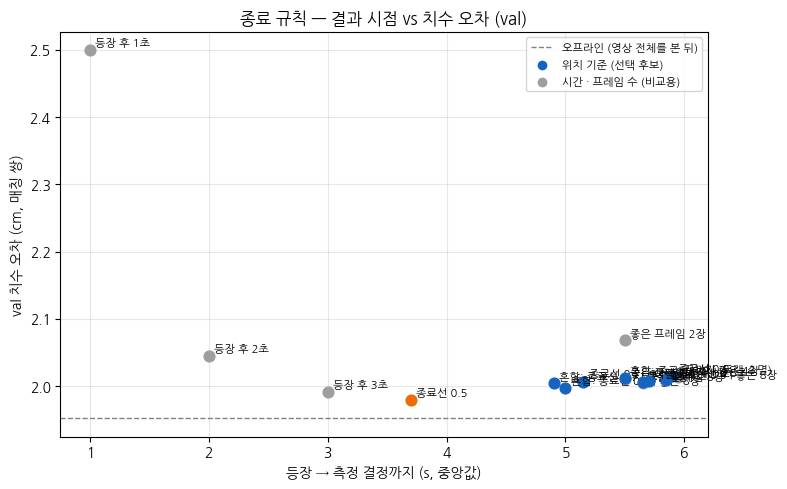


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 중복 방지 효과 (val) — 끈 경우 vs 켠 경우


,결과 낸 트랙,매칭,미검출,정답 없음,그중 중복 측정,② cm,③ cm,뺀 트랙,그중 다른 상자
끝까지 (트랙 소멸) · 중복 방지 끔,466.0,457.0,10.0,9.0,2.0,2.013,2.712,NaN,NaN
끝까지 (트랙 소멸) · 중복 방지 켬,464.0,456.0,11.0,8.0,1.0,2.014,2.768,2.0,1.0
종료선 0.5 · 중복 방지 끔,466.0,457.0,10.0,9.0,2.0,1.979,2.678,NaN,NaN
종료선 0.5 · 중복 방지 켬,464.0,456.0,11.0,8.0,1.0,1.979,2.735,2.0,1.0


💾 /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/step2/online/online_rules_val.csv · chosen_rule.json · rules_val.png


In [15]:
# [O-2] val — 종료 규칙 비교 · 결과 시점 vs 치수 오차 · 규칙 선택 (val만으로, 기준은 실험 전에 고정)
#  - 영상마다 process_video (처음 한 번만 YOLO · 추적 · 인코딩, 이후 ONLINE_DIR 캐시)
#  - 기준 규칙 '끝까지 (트랙 소멸)' = 온라인에서 오프라인에 가장 가까운 방식 (트랙이 사라질 때까지 모든 관측)
#  - 선택 기준 (고정): 속도와 무관한 규칙(위치 기준: 종료선 · 이탈 직전 · 위치가 들어간 혼합) 중에서,
#                     ② cm(같은 상자끼리)와 ③ cm가 '끝까지'보다 0.03 cm 넘게 나빠지지 않는 것 가운데
#                     결정까지 시간(중앙값)이 가장 짧은 것. 없으면 '끝까지'
#    (시간 · 프레임 수 규칙은 컨베이어 속도가 다르면 의미가 달라져 비교용으로만 표시)
#  - 모든 규칙에 중복 방지 적용 (DEDUP). 끈 경우와의 비교는 아래 표
from collections import Counter
SEL_TOL, REF_RULE = 0.03, '끝까지 (트랙 소멸)'
LINK = {}


def run_split(sp):
    vids = [v for v in sorted(LABELS[sp]) if v in RECS[sp] and RECS[sp][v]['quad'] is not None]
    RES, t0 = {}, time.time()
    for i, vid in enumerate(vids):
        RES[vid] = process_video(sp, vid); LINK[(sp, vid)] = link_cache(sp, vid, RES[vid]['tracks'])
        if (i + 1) % 10 == 0 or i + 1 == len(vids):
            print(f'  {sp}: {i + 1}/{len(vids)} 영상 · {time.time() - t0:.0f}s')
    return RES


def track_agreement(sp, RES):
    rows = []
    for vid, R in RES.items():
        link, _ = LINK[(sp, vid)]; long_tr = {t for t, x in R['tracks'].items() if len(x['fi']) >= MIN_OBS}
        cnt = Counter(link[t] for t in long_tr if t in link)
        rows.append({'캐시 트랙': len(RECS[sp][vid]['tracks']), '온라인 트랙 (2장 이상)': len(long_tr), '연결된 캐시 트랙': len(cnt),
                     '쪼개진 캐시 트랙 (온라인 2개 이상)': sum(v >= 2 for v in cnt.values()), '캐시와 연결 없는 온라인 트랙': len(long_tr - set(link)),
                     'max_miss': R['inst']['max_miss']})
    D = pd.DataFrame(rows).sum().astype(float); D['max_miss'] = np.mean([R['inst']['max_miss'] for R in RES.values()])
    D['캐시 트랙 일치율 %'] = D['연결된 캐시 트랙'] / D['캐시 트랙'] * 100
    return D


hr('▶ [O-2] val 처리 (영상마다 검출 · 설치 · 스트리밍 추적 · crop 예측 — 캐시가 있으면 읽기만)')
RES_V = run_split('val')
hr('▶ 트랙이 기존(오프라인 캐시)과 같게 나오나 — val 전체 합')
display(track_agreement('val', RES_V).round(1).to_frame('val'))

def speed_table(sp, RES):
    """영상마다 컨베이어 속도 · ROI 통과 시간 → 같은 '3초'가 영상마다 ROI의 몇 %인지"""
    rows = []
    for vid, R in RES.items():
        I = R['inst']; tr = (I['pmax'] - I['pmin']) / max(I['speed'], 1e-6) * DT
        dur = [(t['fi'][-1] - t['fi'][0]) * DT for t in R['tracks'].values() if len(t['fi']) >= MIN_OBS]
        rows.append({'vid': vid, '컨베이어 속도 px/s': I['speed'] / DT, 'ROI 길이 px (진행 방향)': I['pmax'] - I['pmin'],
                     'ROI 통과 시간 s': tr, '3초 = 통과의 %': 3 / tr * 100, '트랙이 보인 시간 s (중앙값)': np.median(dur) if dur else np.nan})
    return pd.DataFrame(rows).set_index('vid')


SPD_V = speed_table('val', RES_V)
hr('▶ 컨베이어 속도 진단 (val) — 같은 시간 기준이 영상마다 다른 의미')
display(SPD_V.describe().loc[['min', '25%', '50%', '75%', 'max']].round(2))
print(f"  ROI 통과 시간 {SPD_V['ROI 통과 시간 s'].min():.1f} ~ {SPD_V['ROI 통과 시간 s'].max():.1f} s → '등장 후 3초'는 "
      f"통과의 {SPD_V['3초 = 통과의 %'].min():.0f} ~ {SPD_V['3초 = 통과의 %'].max():.0f}% 지점. 위치 기준(종료선 L)은 모든 영상에서 같은 지점")

R_OFF_V = offline_rows('val')
print(f"오프라인 최종 재현: val ② {R_OFF_V[R_OFF_V.kind == '매칭'].cm.mean():.3f} cm (기대 1.952) · ③ {R_OFF_V.cm.mean():.3f} cm")
# 중복 방지를 켤지: 기준 규칙('끝까지')의 val ③이 켰을 때 더 낮으면 켬 (규칙 선택 전에 먼저 정함)
_d3 = {on: summary_row(*score_rule('val', REF_RULE, RES_V, dedup=on))['③ cm'] for on in (False, True)}
DEDUP = bool(_d3[True] < _d3[False])
print(f"중복 방지: 끔 ③ {_d3[False]:.3f} · 켬 ③ {_d3[True]:.3f} cm ('끝까지', val) → {'켬' if DEDUP else '끔'}")
OUT_V = {rn: score_rule('val', rn, RES_V) for rn in RULES}
rows = {}
for rn, (R, T, nd) in OUT_V.items():
    r = {'종류': rule_kind(RULES[rn]), '선택 후보': '○' if rn in SELECTABLE else '', **summary_row(R, T, nd),
         '중복 방지로 뺌': SUPP[('val', rn, None)][0], '그중 다른 상자': SUPP[('val', rn, None)][1]}
    d, lo, hi, n = paired_box(OUT_V[REF_RULE][0], R); r['② − 끝까지 (같은 상자)'] = f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}]'; r['_d2'] = d
    d, lo, hi, n = paired_box(R_OFF_V, R); r['② − 오프라인 (같은 상자)'] = f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}] · {n}개'
    r['_d3'] = r['③ cm'] - summary_row(*OUT_V[REF_RULE])['③ cm']; rows[rn] = r
TAB_V = pd.DataFrame(rows).T
hr('▶ [O-2] val — 종료 규칙별 치수 오차 · 결과 시점 (결정까지 = 등장 → 측정 발동, 치수 추정 계산 시간 약 0.19 s는 [O-4])')
display(TAB_V.drop(columns=['_d2', '_d3']).round(3))

ok = [rn for rn in RULES if rn in SELECTABLE and TAB_V.loc[rn, '_d2'] <= SEL_TOL and TAB_V.loc[rn, '_d3'] <= SEL_TOL]
CHOSEN = min(ok, key=lambda rn: (TAB_V.loc[rn, '결정까지 s (중앙값)'], TAB_V.loc[rn, '② cm'])) if ok else REF_RULE
print(f"\n선택 후보(위치 기준) 중 기준을 만족한 규칙 ({len(ok)}개): {ok}")
print(f"→ 선택: {CHOSEN} · 결정까지 중앙값 {TAB_V.loc[CHOSEN, '결정까지 s (중앙값)']:.1f} s "
      f"(끝까지 {TAB_V.loc[REF_RULE, '결정까지 s (중앙값)']:.1f} s) · val ② {TAB_V.loc[CHOSEN, '② cm']:.3f} cm")

fig, ax = plt.subplots(figsize=(8, 5))
for rn in RULES:
    x, y = TAB_V.loc[rn, '결정까지 s (중앙값)'], TAB_V.loc[rn, '② cm']
    ax.scatter(x, y, s=60, c='#ef6c00' if rn == CHOSEN else ('#1565c0' if rn in SELECTABLE else '#9e9e9e'), zorder=3); ax.annotate(rn, (x, y), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.axhline(R_OFF_V[R_OFF_V.kind == '매칭'].cm.mean(), ls='--', c='gray', lw=1, label='오프라인 (영상 전체를 본 뒤)')
ax.set_xlabel('등장 → 측정 결정까지 (s, 중앙값)'); ax.set_ylabel('val 치수 오차 (cm, 매칭 쌍)'); ax.set_title('종료 규칙 — 결과 시점 vs 치수 오차 (val)')
ax.scatter([], [], c='#1565c0', label='위치 기준 (선택 후보)'); ax.scatter([], [], c='#9e9e9e', label='시간 · 프레임 수 (비교용)')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(f'{ONLINE_DIR}/rules_val.png', dpi=150); plt.show()

hr('▶ 중복 방지 효과 (val) — 끈 경우 vs 켠 경우')
rows = {}
for rn in dict.fromkeys([REF_RULE, CHOSEN]):  # noqa
    for on in (False, True):
        R_, T_, nd_ = score_rule('val', rn, RES_V, dedup=on); r_ = summary_row(R_, T_, nd_)
        rows[f'{rn} · 중복 방지 {"켬" if on else "끔"}'] = {k: r_[k] for k in ('결과 낸 트랙', '매칭', '미검출', '정답 없음', '그중 중복 측정', '② cm', '③ cm')} | \
            ({'뺀 트랙': SUPP[('val', rn, True)][0], '그중 다른 상자': SUPP[('val', rn, True)][1]} if on else {})
display(pd.DataFrame(rows).T.round(3))
SPD_V.to_csv(f'{ONLINE_DIR}/speed_val.csv')
TAB_V.drop(columns=['_d2', '_d3']).to_csv(f'{ONLINE_DIR}/online_rules_val.csv')
json.dump({'rule': CHOSEN, 'params': RULES[CHOSEN], 'dedup': DEDUP, 'time': time.strftime('%Y-%m-%d %H:%M'), 'tol': SEL_TOL},
          open(f'{ONLINE_DIR}/chosen_rule.json', 'w'), ensure_ascii=False, indent=1)
print(f'💾 {ONLINE_DIR}/online_rules_val.csv · chosen_rule.json · rules_val.png')


# **3. test — 고른 규칙 하나만 한 번**

In [16]:
# [O-3] test — [O-2]에서 고른 규칙 하나만 한 번 채점 (최종 모델은 그대로, 처리 방식만 온라인)
#  - 오프라인 최종 test ② 1.751 cm와 같은 상자끼리 비교. 기록: ONLINE_DIR/ONLINE_TEST_SCORED.txt
if 'test' in SPLITS:
    _cj = json.load(open(f'{ONLINE_DIR}/chosen_rule.json')); CH, DEDUP = _cj['rule'], _cj.get('dedup', True)
    MARK_O = f'{ONLINE_DIR}/ONLINE_TEST_SCORED.txt'
    if os.path.exists(MARK_O): print('⚠️ 온라인 test는 이미 채점된 적이 있음:', open(MARK_O).read().strip())
    hr(f'▶ [O-3] test 처리 · 채점 — 규칙: {CH} · 중복 방지 {"켬" if DEDUP else "끔"}')
    RES_T = run_split('test')
    display(track_agreement('test', RES_T).round(1).to_frame('test'))
    SPD_T = speed_table('test', RES_T); SPD_T.to_csv(f'{ONLINE_DIR}/speed_test.csv')
    print(f"  test ROI 통과 시간 {SPD_T['ROI 통과 시간 s'].min():.1f} ~ {SPD_T['ROI 통과 시간 s'].max():.1f} s")
    R_T, T_T, nd_T = score_rule('test', CH, RES_T); R_OFF_T = offline_rows('test')
    row = {**summary_row(R_T, T_T, nd_T), '중복 방지로 뺌': SUPP[('test', CH, None)][0], '그중 다른 상자': SUPP[('test', CH, None)][1]}
    mt = R_T[R_T.kind == '매칭']
    lo, hi = boot_ci(mt, 'cm'); row['② cm 95% CI'] = f'[{lo:.2f}, {hi:.2f}]'
    d, lo, hi, n = paired_box(R_OFF_T, R_T); row['② − 오프라인 (같은 상자)'] = f'{d:+.3f} [{lo:+.3f}, {hi:+.3f}] · {n}개'
    off = {'② cm': R_OFF_T[R_OFF_T.kind == '매칭'].cm.mean(), '③ cm': R_OFF_T.cm.mean(), '① w cm': R_OFF_T[R_OFF_T.kind == '매칭'].w_cm.mean()}
    display(pd.DataFrame({f'온라인 ({CH})': row, '오프라인 최종': off}).T)
    with open(MARK_O, 'a') as f_:
        f_.write(f"{time.strftime('%Y-%m-%d %H:%M')} {CH} · 중복 방지 {DEDUP} · ② {row['② cm']:.3f} · ③ {row['③ cm']:.3f} · 결정까지 중앙값 {row['결정까지 s (중앙값)']:.2f} s\n")
    pd.DataFrame({'online': row}).T.to_csv(f'{ONLINE_DIR}/online_test.csv'); print(f'💾 {ONLINE_DIR}/online_test.csv')
else:
    print('⏭ test 없음 (SPLITS)')


⚠️ 온라인 test는 이미 채점된 적이 있음: 2026-11-14 04:39 등장 후 3초 · ② 1.805 · ③ 2.684 · 결정까지 중앙값 3.00 s
2026-11-14 04:46 등장 후 3초 · ② 1.805 · ③ 2.684 · 결정까지 중앙값 3.00 s
2026-11-14 05:01 종료선 0.5 · ② 1.804 · ③ 2.690 · 결정까지 중앙값 3.70 s

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [O-3] test 처리 · 채점 — 규칙: 종료선 0.5 · 중복 방지 끔
  test: 10/50 영상 · 7s
  test: 20/50 영상 · 14s
  test: 30/50 영상 · 21s
  test: 40/50 영상 · 28s
  test: 50/50 영상 · 35s


,test
캐시 트랙,477.0
온라인 트랙 (2장 이상),489.0
연결된 캐시 트랙,473.0
쪼개진 캐시 트랙 (온라인 2개 이상),10.0
캐시와 연결 없는 온라인 트랙,5.0
max_miss,36.0
캐시 트랙 일치율 %,99.2


  test ROI 통과 시간 5.2 ~ 18.6 s


,결과 낸 트랙,매칭,미검출,정답 없음,그중 중복 측정,① w cm,② cm,② %,③ cm,③ %,결정까지 s (중앙값),결정까지 s (90%),보이는 동안 결정 %,중복 방지로 뺌,그중 다른 상자,② cm 95% CI,② − 오프라인 (같은 상자)
온라인 (종료선 0.5),489,468,8,21,11,1.172736,1.802364,9.164936,2.683178,14.465171,3.7,5.22,76.687117,0,0,"[1.62, 1.99]","+0.054 [-0.005, +0.125] · 468개"
오프라인 최종,NaN,NaN,NaN,NaN,NaN,1.024105,1.750553,NaN,2.155411,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


💾 /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/step2/online/online_test.csv


# **4. 실시간 루프 — 진짜 한 프레임씩 처리하며 시간 측정**

In [27]:
# [O-4a] 실시간 루프 정의 — head 로드 · 배치 치수 추정 · 스레드 작업자 · run_stream (측정은 [O-4b], 시각화는 [O-5])
#  - 이 셀은 몇 초면 끝남. [O-5]만 다시 돌릴 때도 이 셀을 먼저 실행
#  - 실제 카메라처럼: 0.1초마다 프레임이 도착 (그 시각까지 기다렸다가 처리, 늦으면 바로 처리 → 지연이 쌓이면 그대로 보임)
#  - 검출 · 추적 루프: 프레임 grab (0.1초마다 decode) → ROI crop → YOLO (batch 1) → 추적 → 가려짐 · crop 저장
#                      → 종료 규칙 · 중복 방지로 측정할 상자를 정함 (여기까지 루프가 직접)
#  - 치수 추정 (DA3 + DINOv3 + head 10개, TTA) — 두 방식 비교
#      동기 · 배치   : 같은 프레임에 발동한 상자를 한 배치로 묶어 루프 안에서 바로 계산 (루프가 기다림)
#      스레드 · 배치 : 별도 스레드 · 별도 CUDA stream이 계산. 기다리는 상자를 모두 한 배치로 묶음 (루프는 안 기다림)
#  - 설치 1회 값(ROI · 컨베이어 속도 · max_miss)은 [O-2] · [O-3] 캐시를 그대로 씀 (측정 전에 끝났다고 봄 → 시간에 안 넣음)
#  - 실시간 판정 (이전과 같은 기준): 모든 영상에서 처리 배율 < 1 이고 루프 지연(도착 → 처리 끝)이 0.5 s 넘게 쌓이지 않음
#  - [O-2] · [O-3]의 배치 계산과 결과가 같은지 확인 (YOLO batch 1 vs 16 차이 외에는 같아야 함)
import threading, queue, contextlib
O_RN = 10
O_SP = 'test' if 'test' in SPLITS else 'val'
_cj = json.load(open(f'{ONLINE_DIR}/chosen_rule.json')); CH, DEDUP = _cj['rule'], _cj.get('dedup', True); RULE_CH = RULES[CH]
_sizes = sorted(RECS[O_SP], key=lambda v: len(RECS[O_SP][v]['tracks']))
O_VIDS = [v for v in [_sizes[i] for i in np.linspace(0, len(_sizes) - 1, O_RN).round().astype(int)] if RECS[O_SP][v]['quad'] is not None]

HEADS_F = {}
for key, cfg in (('s1', STEP1), ('s2', STEP2)):
    HEADS_F[key] = []
    for k in range(N_FOLD):
        ck = torch.load(f"{CKPT2}/{cfg['name']}_fold{k}.pt", map_location='cpu', weights_only=False)
        h = TokHead(np.zeros(len(cfg['tgt'])), len(cfg['side']), 49, 2048).to(DEV).eval(); h.load_state_dict(ck['state'])
        HEADS_F[key].append((h, torch.tensor(ck['mu'], device=DEV), torch.tensor(ck['sd'], device=DEV)))
SIZE_STREAM = torch.cuda.Stream() if DEV == 'cuda' else None


@torch.no_grad()
def size_crops(crops, ft):
    """crop (N, 224, 224, 3) + 보조 입력 표 → crop마다 (log w, log d/w, log h/w). infer_head(fold < 0)와 같은 계산"""
    tok = encode(crops, ENC_F, BEST_BS, tta=True).half().float(); N = len(crops); out = []
    for key, cfg in (('s1', STEP1), ('s2', STEP2)):
        A = torch.tensor(ft[cfg['side']].values, dtype=torch.float32, device=DEV)
        si = cfg['side'].index('sin_t') if 'sin_t' in cfg['side'] else None; acc = 0
        for h, mu, sd in HEADS_F[key]:
            s = (A - mu) / sd; sf = s.clone()
            if si is not None: sf[:, si] *= -1
            acc = acc + (h(tok[:N], s) + h(tok[N:], sf)) / 2
        out.append((acc / N_FOLD).cpu().numpy())
    return np.log(ft.w_base.values) + out[0][:, 0], out[1][:, 0], out[1][:, 1]


def size_batch(sp, vid, items):
    """items: [(tid, crops (k, 224, 224, 3), boxes (k, 4))] 여러 상자 → crop을 모두 한 배치로 → 상자마다 w · d · h"""
    crops = np.concatenate([c for _, c, _ in items]); boxes = np.concatenate([b for _, _, b in items])
    lw, ldw, lhw = size_crops(crops, feat_table(sp, vid, boxes)); out, i = {}, 0
    for tid, c, _ in items:
        k = len(c); w = float(np.exp(lw[i:i + k].mean()))
        out[tid] = dict(w=w, d=w * float(np.exp(ldw[i:i + k].mean())), h=w * float(np.exp(lhw[i:i + k].mean()))); i += k
    return out


class SizingWorker:
    """별도 스레드: 큐에 쌓인 상자를 모두 꺼내 한 배치로 계산 (별도 CUDA stream → 검출 · 추적과 GPU를 같이 씀)"""
    def __init__(self, sp, vid):
        self.sp, self.vid, self.q, self.res, self.batches = sp, vid, queue.Queue(), {}, []
        self.th = threading.Thread(target=self._run, daemon=True); self.th.start()

    def submit(self, items): self.q.put(items)

    def close(self):
        self.q.put(None); self.th.join()

    def _run(self):
        stop = False
        while not stop:
            job = self.q.get()
            if job is None: break
            items = list(job)
            while True:                                                     # 기다리는 상자를 모두 한 배치로
                try: j = self.q.get_nowait()
                except queue.Empty: break
                if j is None: stop = True; break
                items += j
            t0 = time.perf_counter()
            with (torch.cuda.stream(SIZE_STREAM) if SIZE_STREAM is not None else contextlib.nullcontext()):
                out = size_batch(self.sp, self.vid, items)
            if SIZE_STREAM is not None: SIZE_STREAM.synchronize()
            t1 = time.perf_counter(); self.batches.append((len(items), t1 - t0))
            for tid, r in out.items(): self.res[tid] = {**r, 't_done': t1}


def run_stream(sp, vid, rule, R0, mode, rec=None):
    """mode: 'sync' (동기 · 배치) / 'async' (스레드 · 배치). 0.1초마다 프레임이 도착하는 것처럼 속도를 맞춤
       rec(dict)를 주면 프레임마다 화면 상태를 기록 ([O-5] 시각화용: 관측 bbox · 측정 발동 · 결과가 나온 상자 · 지연)"""
    roi, inst = R0['roi'], R0['inst']; cap = cv2.VideoCapture(video_path(sp, vid))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0; step = max(int(round(fps * DT)), 1)
    ot = OnlineTracker(inst, roi); buf, fired, measured, supp, first = {}, {}, set(), {}, {}
    hist = defaultdict(lambda: ([], [])); lag, proc, sync_res, sync_b = [], [], {}, []
    worker = SizingWorker(sp, vid) if mode == 'async' else None

    def decide(tid, n_now, todo):
        B = buf[tid]; sel = select_frames(np.array(B['bbox']), np.array(B['occ']))
        if not sel: return
        if DEDUP:
            e = find_dup(hist[tid][0], hist[tid][1], n_now, [(x, hist[x][0], hist[x][1]) for x in measured], inst)
            if e is not None: supp[tid] = e; return
        measured.add(tid); first[tid] = B['fi'][0]
        if rec is not None: rec.setdefault('sel', {})[tid] = [(B['fi'][j], B['bbox'][j], B['occ'][j]) for j in sel]   # 시각화: 쓴 관측
        todo.append((tid, np.stack([B['crop'][j] for j in sel]), np.array(B['bbox'])[sel]))

    def flush(todo, n_now):
        if not todo: return
        if worker is not None: worker.submit(todo); return
        t0 = time.perf_counter(); out = size_batch(sp, vid, todo); _sync(); t1 = time.perf_counter()
        sync_b.append((len(todo), t1 - t0))
        for tid, r in out.items(): sync_res[tid] = {**r, 't_done': t1}

    n = i = 0; T0 = time.perf_counter() + 0.05; arr = lambda k: T0 + k * DT
    if rec is not None: rec.update(T0=T0, frames=[])
    while True:
        now = time.perf_counter()
        if now < arr(n): time.sleep(arr(n) - now)                           # 프레임 n이 카메라에서 도착하는 시각
        ok_ = True
        while i % step:                                                     # 사이 프레임은 grab만
            ok_ = cap.grab(); i += 1
            if not ok_: break
        if not ok_ or not cap.grab(): break
        i += 1; ok_, fr = cap.retrieve()
        if not ok_: break
        seen, dead = ot.step(detect([fr[roi[1]:roi[3], roi[0]:roi[2]]], 1)[0], n); todo = []
        for tid, b, o, g, fr_, te in observe(seen, inst, roi):
            hist[tid][0].append(n); hist[tid][1].append(b)
            if tid in fired: continue
            B = buf.setdefault(tid, {k: [] for k in ('fi', 'bbox', 'occ', 'good', 'frac', 'tte', 'crop')})
            for k_, v_ in zip(('fi', 'bbox', 'occ', 'good', 'frac', 'tte'), (n, b, o, g, fr_, te)): B[k_].append(v_)
            B['crop'].append(crop_box(fr, b)); j = len(B['fi']) - 1
            if j + 1 >= MIN_OBS and cond(rule, B, j):
                fired[tid] = n; decide(tid, n, todo)
        for tid in dead:
            if tid not in fired and tid in buf and len(buf[tid]['fi']) >= MIN_OBS:
                fired[tid] = n; decide(tid, n, todo)
        flush(todo, n); _sync()
        t_end = time.perf_counter(); lag.append(t_end - arr(n)); proc.append(t_end - max(arr(n), now))
        if rec is not None:
            done = set(worker.res) if worker is not None else set(sync_res)
            rec['frames'].append({'n': n, 'seen': [(t, b.copy()) for t, b in seen],
                                  'fired': set(fired), 'done': done, 'supp': set(supp), 'lag': lag[-1]})
        n += 1
    cap.release(); todo = []
    for tid in list(buf):                                                   # 영상 끝 (실제 스트림에는 없음)
        if tid not in fired and len(buf[tid]['fi']) >= MIN_OBS:
            fired[tid] = n; decide(tid, n, todo)
    flush(todo, n)
    if worker is not None: worker.close()
    res, batches = (worker.res, worker.batches) if worker is not None else (sync_res, sync_b)
    lat = {t: r['t_done'] - arr(first[t]) for t, r in res.items()}            # 상자가 처음 보인 프레임 도착 → 치수 나옴
    return res, np.array(lag), np.array(proc), lat, batches, n, supp


In [22]:
# [O-4b] 실시간 측정 — [O-4a]의 run_stream으로 test 영상 O_RN개 × 두 방식 (A100 권장 · 영상 길이만큼 걸림)
hr(f'▶ [O-4] 실시간 스트리밍 — {O_SP} 영상 {len(O_VIDS)}개 · 규칙 {CH} · 중복 방지 {"켬" if DEDUP else "끔"} ({torch.cuda.get_device_name(0)})')
R0s = {v: process_video(O_SP, v) for v in O_VIDS}                          # 설치 1회 값 (캐시)
for m in ('sync', 'async'):
    run_stream(O_SP, O_VIDS[0], RULE_CH, R0s[O_VIDS[0]], m)                 # warmup
MODES = {'sync': '동기 · 배치', 'async': '스레드 · 배치'}
rows, LATS = [], {m: [] for m in MODES}
for vid in O_VIDS:
    rb = rule_results(R0s[vid], CH)
    for m, mname in MODES.items():
        res, lag, proc, lat, batches, n, supp = run_stream(O_SP, vid, RULE_CH, R0s[vid], m); LATS[m] += list(lat.values())
        common = set(rb) & set(res)
        rows.append({'vid': vid, '방식': mname, '영상 길이 s': n * DT, '측정한 상자': len(res), '중복 방지로 뺌': len(supp),
                     '루프 처리 ms/프레임 (평균)': proc.mean() * 1000, '루프 처리 ms/프레임 (최대)': proc.max() * 1000,
                     '실시간 배율': proc.sum() / (n * DT), '루프 지연 s (최대)': lag.max(),
                     '배치 수': len(batches), '배치당 상자 (평균)': np.mean([b[0] for b in batches]) if batches else np.nan,
                     '배치 계산 ms (평균)': np.mean([b[1] for b in batches]) * 1000 if batches else np.nan,
                     '등장 → 결과 s (평균)': np.mean(list(lat.values())) if lat else np.nan,
                     '등장 → 결과 s (최대)': np.max(list(lat.values())) if lat else np.nan,
                     '배치 계산과 같은 상자 %': len(common) / max(len(rb), 1) * 100,
                     '배치 계산과 w 차이 cm': np.mean([abs(res[t]['w'] - rb[t]['w']) for t in common]) if common else np.nan})
    print(f"  {vid}: " + ' · '.join(f"{r['방식']} 지연 최대 {r['루프 지연 s (최대)']:.2f}s" for r in rows[-2:]))
OR = pd.DataFrame(rows).set_index(['vid', '방식']); display(OR.round(3))

hr('▶ [O-4] 요약 — 방식별')
SUM_O = {}
for m, mname in MODES.items():
    d = OR.xs(mname, level='방식'); L = LATS[m]
    SUM_O[mname] = {'루프 처리 ms/프레임 (평균)': d['루프 처리 ms/프레임 (평균)'].mean(), '루프 처리 ms/프레임 (최대)': d['루프 처리 ms/프레임 (최대)'].max(),
                    '실시간 배율 (최대)': d['실시간 배율'].max(), '루프 지연 s (최대)': d['루프 지연 s (최대)'].max(),
                    '배치당 상자 (평균)': d['배치당 상자 (평균)'].mean(), '배치 계산 ms (평균)': d['배치 계산 ms (평균)'].mean(),
                    '등장 → 결과 s (평균)': float(np.mean(L)), '등장 → 결과 s (90%)': float(np.quantile(L, 0.9)),
                    '등장 → 결과 s (최대)': float(np.max(L)), '배치 계산과 같은 상자 %': d['배치 계산과 같은 상자 %'].mean()}
    SUM_O[mname]['실시간'] = '✅' if SUM_O[mname]['실시간 배율 (최대)'] < 1 and SUM_O[mname]['루프 지연 s (최대)'] < 0.5 else '✗'
display(pd.DataFrame(SUM_O).round(3))
print(f'※ 실시간 = 모든 영상에서 처리 배율 < 1 이고 루프 지연이 0.5 s 넘게 쌓이지 않음 · 프레임 간격 {DT * 1000:.0f} ms · '
      '이전(상자마다 따로 · 동기) 결과: 최대 지연 0.77 s')
json.dump({'gpu': torch.cuda.get_device_name(0), 'rule': CH, 'dedup': DEDUP, 'split': O_SP,
           'per_video': OR.reset_index().to_dict('records'), 'summary': SUM_O},
          open(f'{ONLINE_DIR}/online_runtime.json', 'w'), ensure_ascii=False, indent=1, default=float)
print(f'💾 {ONLINE_DIR}/online_runtime.json')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [O-4] 실시간 스트리밍 — test 영상 10개 · 규칙 종료선 0.5 · 중복 방지 끔 (NVIDIA A100-SXM4-80GB)
  test_025: 동기 · 배치 지연 최대 0.23s · 스레드 · 배치 지연 최대 0.14s
  test_012: 동기 · 배치 지연 최대 0.22s · 스레드 · 배치 지연 최대 0.13s
  test_020: 동기 · 배치 지연 최대 0.22s · 스레드 · 배치 지연 최대 0.12s
  test_014: 동기 · 배치 지연 최대 0.26s · 스레드 · 배치 지연 최대 0.14s
  test_000: 동기 · 배치 지연 최대 0.23s · 스레드 · 배치 지연 최대 0.12s
  test_011: 동기 · 배치 지연 최대 0.24s · 스레드 · 배치 지연 최대 0.13s
  test_028: 동기 · 배치 지연 최대 0.23s · 스레드 · 배치 지연 최대 0.14s
  test_026: 동기 · 배치 지연 최대 0.24s · 스레드 · 배치 지연 최대 0.13s
  test_004: 동기 · 배치 지연 최대 0.48s · 스레드 · 배치 지연 최대 0.32s
  test_038: 동기 · 배치 지연 최대 0.32s · 스레드 · 배치 지연 최대 0.14s


영상 길이 s  측정한 상자  중복 방지로 뺌  루프 처리 ms/프레임 (평균)  \
vid      방식                                                       
test_025 동기 · 배치       5.3       2         0             33.154   
         스레드 · 배치      5.3       2         0             29.817   
test_012 동기 · 배치       5.3       5         0             40.672   
         스레드 · 배치      5.3       5         0             34.175   
test_020 동기 · 배치       8.3       6         0             35.807   
         스레드 · 배치      8.3       6         0             30.839   
test_014 동기 · 배치       7.1       9         0             44.797   
         스레드 · 배치      7.1       9         0             34.020   
test_000 동기 · 배치       7.7       9         0             42.860   
         스레드 · 배치      7.7       9         0             33.790   
test_011 동기 · 배치      10.7      10         0             38.950   
         스레드 · 배치     10.7      10         0             32.905   
test_028 동기 · 배치      11.3      10         0             39.281   
         스레드 · 배치     11.3      10         0             32.876   
test_026 동기 · 배치      12.5      12         0             38.536   
         스레드 · 배치     12.5      12         0             32.645   
test_004 동기 · 배치      10.7      16         0             49.591   
         스레드 · 배치     10.7      16         0             39.098   
test_038 동기 · 배치      15.5      22         0             48.389   
         스레드 · 배치     15.5      22         0             38.171   

                   루프 처리 ms/프레임 (최대)  실시간 배율  루프 지연 s (최대)  배치 수  배치당 상자 (평균)  \
vid      방식                                                                     
test_025 동기 · 배치             233.208   0.332         0.233     2        1.000   
         스레드 · 배치            141.341   0.298         0.141     2        1.000   
test_012 동기 · 배치             216.535   0.407         0.217     5        1.000   
         스레드 · 배치            126.954   0.342         0.127     5        1.000   
test_020 동기 · 배치             216.671   0.358         0.217     6        1.000   
         스레드 · 배치            117.261   0.308         0.117     6        1.000   
test_014 동기 · 배치             231.443   0.448         0.258     9        1.000   
         스레드 · 배치            139.035   0.340         0.139     9        1.000   
test_000 동기 · 배치             231.722   0.429         0.232     8        1.125   
         스레드 · 배치            117.754   0.338         0.118     8        1.125   
test_011 동기 · 배치             240.598   0.389         0.241     8        1.250   
         스레드 · 배치            133.859   0.329         0.134     8        1.250   
test_028 동기 · 배치             229.578   0.393         0.230     9        1.111   
         스레드 · 배치            140.930   0.329         0.141     9        1.111   
test_026 동기 · 배치             240.026   0.385         0.240     9        1.333   
         스레드 · 배치            131.237   0.326         0.131     9        1.333   
test_004 동기 · 배치             421.617   0.496         0.477    14        1.143   
         스레드 · 배치            322.607   0.391         0.323    14        1.143   
test_038 동기 · 배치             237.484   0.484         0.316    19        1.158   
         스레드 · 배치            140.627   0.382         0.141    19        1.158   

                   배치 계산 ms (평균)  등장 → 결과 s (평균)  등장 → 결과 s (최대)  \
vid      방식                                                        
test_025 동기 · 배치         196.666           3.372           3.812   
         스레드 · 배치        210.596           3.388           3.826   
test_012 동기 · 배치         177.174           2.799           3.815   
         스레드 · 배치        182.489           2.807           3.830   
test_020 동기 · 배치         172.792           3.629           4.314   
         스레드 · 배치        178.754           3.636           4.325   
test_014 동기 · 배치         172.110           3.699           6.318   
         스레드 · 배치        178.980           3.702           6.323   
test_000 동기 · 배치         204.982           3.975           4.715   
         스레드 


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [O-4] 요약 — 방식별


,동기 · 배치,스레드 · 배치
루프 처리 ms/프레임 (평균),41.203737,33.833732
루프 처리 ms/프레임 (최대),421.617368,322.606809
실시간 배율 (최대),0.495914,0.39098
루프 지연 s (최대),0.476987,0.322607
배치당 상자 (평균),1.11202,1.11202
배치 계산 ms (평균),199.24528,206.795338
등장 → 결과 s (평균),4.074633,4.078433
등장 → 결과 s (90%),5.339996,5.33962
등장 → 결과 s (최대),7.418207,7.423605
배치 계산과 같은 상자 %,100.0,100.0


※ 실시간 = 모든 영상에서 처리 배율 < 1 이고 루프 지연이 0.5 s 넘게 쌓이지 않음 · 프레임 간격 100 ms · 이전(상자마다 따로 · 동기) 결과: 최대 지연 0.77 s
💾 /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/step2/online/online_runtime.json


# **5. 시각화 — test 영상 하나를 실시간으로 처리하는 모습**

In [28]:
# [O-5] 시각화 — test 영상 하나를 실시간 루프(스레드 · 배치)로 처리하는 모습 그대로 mp4로 저장 + 재생 + 상자별 결과 표
#  - VIS_NUM(test 영상 번호)만 바꿔 다시 실행. 영상은 실제처럼 0.1초마다 처리하므로 영상 길이만큼 걸림
#  - 필요: [O-1] · [O-4a] (그리고 [O-2] 또는 chosen_rule.json). [O-4b] 측정은 안 돌려도 됨
#  - 상자 색: 회색 = 추적 중 · 노랑 = 측정 발동, 계산 중 · 초록 = 치수 나옴 (정답과 비교) · 주황 = 치수 나옴, 정답 없는 트랙
#  - 파란 선 = 종료선 (고른 규칙이 종료선이면 그 위치), 점선 사각형 = ROI
#  - 상단 = 시각 · 검출 · 추적 루프 지연 · 측정 수, 좌하단 = 최근에 나온 치수 (글자는 cv2가 한글을 못 그려 영어)
#  - 영상 끝에 1초: 영상이 끝날 때까지 종료선을 안 넘은 상자는 그때까지의 관측으로 측정 → 마지막 장면에 함께 표시
#  - 영상 아래: 상자별 표 + 대표 crop(치수 추정에 쓴 프레임 중 가려짐이 가장 적은 것) · 가상 3D 상자 (예측 주황 · 정답 초록 점선)
#  - 예측 · 오차는 [O-3] 채점과 같은 연결(온라인 트랙 → 캐시 트랙 → 수작업 매핑)로 정답과 비교
VIS_NUM = 5  #@param {type:"integer"}
VIS_WIDTH = 960  #@param {type:"integer"}
import imageio.v2 as imageio
from IPython.display import Video
import inspect
assert 'rec' in inspect.signature(run_stream).parameters, '[O-4a] 셀(새 버전)을 먼저 실행'
if 'LINK' not in globals(): LINK = {}
VIS_SP, VIS_VID = 'test', f'test_{VIS_NUM:03d}'
assert VIS_VID in RECS[VIS_SP] and RECS[VIS_SP][VIS_VID]['quad'] is not None, f'{VIS_VID} 없음 또는 레일 없음'
R0v = process_video(VIS_SP, VIS_VID)
if (VIS_SP, VIS_VID) not in LINK: LINK[(VIS_SP, VIS_VID)] = link_cache(VIS_SP, VIS_VID, R0v['tracks'])
REC = {}
res_v, lag_v, proc_v, lat_v, batches_v, n_v, supp_v = run_stream(VIS_SP, VIS_VID, RULE_CH, R0v, 'async', rec=REC)
T0v = REC['T0']

# ── 정답 연결 ──
link_v, _ = LINK[(VIS_SP, VIS_VID)]
trk2box = {m['trk']: m['box_id'] for m in MAPS[VIS_SP].get(VIS_VID, []) if not m['removed'] and m['trk'] is not None}
gt_by = {g['box_id']: g for g in LABELS[VIS_SP][VIS_VID]['boxes']}
first_seen = {}
for fr_ in REC['frames']:
    for t, _ in fr_['seen']: first_seen.setdefault(t, fr_['n'])
fire_n = {}
for fr_ in REC['frames']:
    for t in fr_['fired']: fire_n.setdefault(t, fr_['n'])
INFO = {}
for tid, r in res_v.items():
    p = np.array([r['w'], r['d'], r['h']]); bid = trk2box.get(link_v.get(tid)); g = gt_by.get(bid)
    gt = np.array([g['w'], g['d'], g['h']]) if g else None
    INFO[tid] = dict(pred=p, gt=gt, err=float(np.abs(sort3(p) - sort3(gt)).mean()) if g else np.nan,
                     t_first=first_seen.get(tid, 0) * DT, t_fire=fire_n.get(tid, n_v) * DT, t_done=r['t_done'] - T0v)

# ── 종료선 (ROI 안에서 진행 방향에 수직인 선) ──
I = R0v['inst']; roi = R0v['roi']; u = I['u']
def exit_line(L):
    p = I['pmin'] + L * (I['pmax'] - I['pmin']); pts = []
    for x in (roi[0], roi[2]):
        if abs(u[1]) > 1e-9:
            y = (p - u[0] * x) / u[1]
            if roi[1] - 1e-6 <= y <= roi[3] + 1e-6: pts.append((x, y))
    for y in (roi[1], roi[3]):
        if abs(u[0]) > 1e-9:
            x = (p - u[1] * y) / u[0]
            if roi[0] - 1e-6 <= x <= roi[2] + 1e-6: pts.append((x, y))
    return [tuple(map(int, q)) for q in pts[:2]] if len(pts) >= 2 else None
LINE = exit_line(RULE_CH['exit']) if 'exit' in RULE_CH else None


def rule_en(r):
    p = [f'exit line {r["exit"]}'] if 'exit' in r else []
    p += [f'pre-exit {r["pre"]}s'] if 'pre' in r else []
    p += [f'{r["sec"]}s after appear'] if 'sec' in r else []
    p += [f'{r["good"]} good frames'] if 'good' in r else []
    return ' | '.join(p) or 'until lost'
fmt = lambda a: 'x'.join(f'{v:.0f}' for v in a)

# ── 영상 그리기 (처리한 프레임만, 10 fps = 실제 속도) ──
FONT = cv2.FONT_HERSHEY_SIMPLEX; cap = cv2.VideoCapture(video_path(VIS_SP, VIS_VID))
fps_ = cap.get(cv2.CAP_PROP_FPS) or 30.0; step_ = max(int(round(fps_ * DT)), 1); frames_out, i, k = [], 0, 0
def put(img, txt, org, col, sc=0.5, th=1):
    (tw, tht), _ = cv2.getTextSize(txt, FONT, sc, th); x, y = org
    cv2.rectangle(img, (x - 2, y - tht - 4), (x + tw + 2, y + 4), (0, 0, 0), -1); cv2.putText(img, txt, (x, y), FONT, sc, col, th, cv2.LINE_AA)
TAIL = int(round(1.0 / DT)); last_raw = None
while k < len(REC['frames']) + TAIL:
    if k < len(REC['frames']):
        ok_, img = cap.read()
        if not ok_: break
        if i % step_:
            i += 1; continue
        i += 1; F_ = REC['frames'][k]; last_raw = img.copy()
    else:                                                                   # 영상 끝 1초: 마지막 장면 + 끝에서 측정된 상자까지
        if last_raw is None: break
        img = last_raw.copy(); F_ = {**REC['frames'][-1], 'done': set(INFO), 'fired': set(REC['frames'][-1]['fired']) | set(INFO)}
    k += 1; n_ = F_['n']; t_now = n_ * DT
    for x in range(roi[0], roi[2], 12): cv2.line(img, (x, roi[1]), (min(x + 6, roi[2]), roi[1]), (200, 200, 200), 1); cv2.line(img, (x, roi[3] - 1), (min(x + 6, roi[2]), roi[3] - 1), (200, 200, 200), 1)
    for y in range(roi[1], roi[3], 12): cv2.line(img, (roi[0], y), (roi[0], min(y + 6, roi[3])), (200, 200, 200), 1); cv2.line(img, (roi[2] - 1, y), (roi[2] - 1, min(y + 6, roi[3])), (200, 200, 200), 1)
    if LINE: cv2.line(img, LINE[0], LINE[1], (255, 140, 0), 2); put(img, f'exit line {RULE_CH["exit"]}', (LINE[0][0] + 4, LINE[0][1] - 6), (255, 160, 40))
    for tid, b in F_['seen']:
        x1, y1, x2, y2 = map(int, b)
        if tid in F_['done'] and tid in INFO:
            inf = INFO[tid]; col = (60, 200, 60) if inf['gt'] is not None else (0, 150, 255)
            lines = [f'T{tid} {fmt(inf["pred"])} cm'] + ([f'GT {fmt(inf["gt"])} err {inf["err"]:.1f}'] if inf['gt'] is not None else ['no GT'])
        elif tid in F_['fired'] and tid not in F_['supp']:
            col, lines = (0, 220, 255), [f'T{tid} measuring...']
        else:
            col, lines = (170, 170, 170), [f'T{tid}']
        cv2.rectangle(img, (x1, y1), (x2, y2), col, 3 if col != (170, 170, 170) else 1)
        for j, txt in enumerate(lines): put(img, txt, (x1 + 2, max(16, y1 - 6 - 18 * (len(lines) - 1 - j))), col)
    cv2.rectangle(img, (0, 0), (img.shape[1], 30), (0, 0, 0), -1)
    cv2.putText(img, f'{VIS_VID} | t {t_now:4.1f}s | loop lag {F_["lag"] * 1000:3.0f} ms | measured {len(F_["done"])} | rule: {rule_en(RULE_CH)}',
                (8, 21), FONT, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    if k > len(REC['frames']): put(img, 'video end: boxes not yet past the exit line are measured with frames so far', (10, 52), (255, 255, 255), 0.6)
    recent = sorted([t for t in F_['done'] if t in INFO], key=lambda t: -INFO[t]['t_done'])[:4]
    for j, t in enumerate(recent):
        inf = INFO[t]; s_ = f'T{t} {fmt(inf["pred"])}' + (f' (err {inf["err"]:.1f} cm)' if inf['gt'] is not None else '') + f' @ {inf["t_done"]:.1f}s'
        put(img, s_, (10, img.shape[0] - 12 - 22 * j), (60, 200, 60) if inf['gt'] is not None else (0, 150, 255), 0.55)
    s = VIS_WIDTH / img.shape[1]
    frames_out.append(cv2.cvtColor(cv2.resize(img, (VIS_WIDTH, int(img.shape[0] * s) // 2 * 2)), cv2.COLOR_BGR2RGB))
cap.release()
VIS_DIR = f'{ONLINE_DIR}/vis'; os.makedirs(VIS_DIR, exist_ok=True); VIS_PATH = f'{VIS_DIR}/{VIS_VID}_online.mp4'
imageio.mimsave(VIS_PATH, frames_out, fps=1 / DT, codec='libx264', quality=7, macro_block_size=2)
hr(f'▶ [O-5] {VIS_VID} — 실시간 처리 ({torch.cuda.get_device_name(0)} · 규칙 {CH} · 루프 지연 최대 {lag_v.max():.2f} s)')
display(Video(VIS_PATH, embed=True, width=VIS_WIDTH))
rows = [{'트랙': t, '처음 보임 s': v['t_first'], '측정 결정 s': v['t_fire'], '치수 나옴 s': v['t_done'],
         '등장 → 결과 s': v['t_done'] - v['t_first'], '예측 w×d×h (cm)': fmt(v['pred']),
         '정답 w×d×h (cm)': fmt(v['gt']) if v['gt'] is not None else '—', '치수 오차 cm': v['err']} for t, v in sorted(INFO.items(), key=lambda x: x[1]['t_done'])]
TBL_O = pd.DataFrame(rows).set_index('트랙')
print(f"상자 {len(TBL_O)}개 · 정답 있는 상자 평균 오차 {TBL_O['치수 오차 cm'].mean():.2f} cm · 등장 → 결과 평균 {TBL_O['등장 → 결과 s'].mean():.2f} s · 💾 {VIS_PATH}")
display(TBL_O.round(2))


# ── 상자별 대표 crop + 가상 3D 상자 (예측 주황 · 정답 초록 점선, 같은 축척) ──
def cuboid(ax, w, d, h, color, ls, label):
    V = np.array([[x, y, z] for x in (0, w) for y in (0, d) for z in (0, h)])
    for a_ in range(8):
        for b_ in range(a_ + 1, 8):
            if np.sum(V[a_] != V[b_]) == 1:
                ax.plot(*zip(V[a_], V[b_]), color=color, ls=ls, lw=2, label=label if (a_, b_) == (0, 1) else None)


tids = list(TBL_O.index); ncol = 4; nrow = math.ceil(len(tids) * 2 / ncol)
fig = plt.figure(figsize=(4.2 * ncol, 3.8 * nrow)); cap = cv2.VideoCapture(video_path(VIS_SP, VIS_VID))
for j, tid in enumerate(tids):
    inf = INFO[tid]; fi, b, oc = min(REC['sel'][tid], key=lambda x: x[2])   # 쓴 관측 중 가려짐이 가장 적은 것
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(fi) * step_); ok_, fr = cap.read()
    ax = fig.add_subplot(nrow, ncol, 2 * j + 1)
    if ok_:
        H_, W_ = fr.shape[:2]; x1, y1, x2, y2 = b; px, py = (x2 - x1) * 0.4, (y2 - y1) * 0.4
        c = fr[int(max(0, y1 - py)):int(min(H_, y2 + py)), int(max(0, x1 - px)):int(min(W_, x2 + px))]
        ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
    ax.axis('off'); ax.set_title(f'T{tid} · 가려짐 {oc:.2f} · {fi * DT:.1f}s', fontsize=10)
    pred, gt = inf['pred'], inf['gt']
    ax3 = fig.add_subplot(nrow, ncol, 2 * j + 2, projection='3d')
    cuboid(ax3, *pred, '#ef6c00', '-', f'예측 {fmt(pred)}')
    if gt is not None: cuboid(ax3, *gt, '#2e7d32', '--', f'정답 {fmt(gt)}')
    L = np.nanmax(np.r_[pred, gt if gt is not None else []]) * 1.05
    ax3.set_xlim(0, L); ax3.set_ylim(0, L); ax3.set_zlim(0, L); ax3.set_box_aspect((1, 1, 1)); ax3.view_init(elev=22, azim=-55)
    ax3.set_xlabel('w'); ax3.set_ylabel('d'); ax3.set_zlabel('h'); ax3.tick_params(labelsize=7); ax3.legend(fontsize=7, loc='upper left')
    ax3.set_title(f'T{tid} · 오차 {inf["err"]:.1f} cm · 결과 {inf["t_done"]:.1f}s' if gt is not None else f'T{tid} · 정답 없음 · 결과 {inf["t_done"]:.1f}s', fontsize=10)
cap.release(); plt.tight_layout(); plt.savefig(f'{VIS_DIR}/{VIS_VID}_online_boxes.png', dpi=120); plt.show()
print(f'💾 {VIS_DIR}/{VIS_VID}_online_boxes.png')


Output hidden; open in https://colab.research.google.com to view.

# **5. 읽는 법 · 보고서 8장 "결과 시점"**
- **속도 진단 ([O-2]):** 영상마다 ROI 통과 시간이 다르면 같은 'N초'가 영상마다 다른 지점 → 위치 기준을 쓰는 이유
- **트랙 일치 ([O-2] 첫 표):** 캐시 트랙 일치율이 높고 쪼개진 트랙이 적으면, 미래 프레임 · 병합 없이도 오프라인과 같은 상자를 따라간다. 쪼개진 트랙은 중복 방지로 다시 재지 않는다 (중복 방지 효과 표: 뺀 트랙 · 그중 다른 상자를 잘못 뺀 수)
- **'끝까지' vs 오프라인:** 처리 방식만 다른 같은 모델 → 차이가 온라인 추적의 비용
- **규칙 표 · 그래프:** 왼쪽 아래일수록 좋음 (빨리 결정하면서 오차가 작음). 고른 규칙의 "결정까지" + [O-4] "치수 추정 ms/상자" = 상자가 나타난 뒤 치수가 나오기까지
- **보이는 동안 결정 %:** 상자가 아직 화면(ROI)에 있을 때 결과가 나온 비율 — 현장에서 그 상자를 분류 · 적재 계획에 바로 쓸 수 있는가
- **[O-4]:** 루프 지연(프레임 도착 → 검출 · 추적 끝)이 쌓이지 않으면 0.1초 간격 스트림을 따라간다. 스레드 방식은 치수 추정이 루프를 막지 않으므로 지연이 검출 · 추적 시간 수준으로 유지되어야 한다. '등장 → 결과'는 상자가 처음 보인 프레임의 도착 시각부터 치수가 나온 시각까지 (결정까지 시간 + 대기 + 계산)
